# Modelagem de risco de crédito

**Pergunta do case.** Qual modelo ordena melhor os clientes por risco e produz probabilidades de evento úteis para agrupá-los em uma régua de crédito?

As tabelas, figuras e mensagens históricas vêm da execução salva no notebook recebido. A auditoria complementar foi calculada sobre o CSV incluído no projeto. As duas versões foram retreinadas nessa base e reproduziram as mesmas probabilidades e classificações por registro. Ao rodar as células, o Jupyter substitui as saídas pelas da base configurada.

## 1. Objetivo e desenho do experimento

Comparamos um Logit com WoE monotônico e um LightGBM sobre os preditores originais selecionados. O desfecho é a coluna binária `target`. A probabilidade do evento é denominada PD. O mesmo conjunto de teste é usado para comparar os dois modelos cliente a cliente.

In [1]:
from credit_risk.config.settings import ProjectPaths

paths = ProjectPaths.discover()

## 2. Carregamento e auditoria dos dados

O leitor preserva a ordem de registros do CSV e a escala dos valores com vírgula decimal. A saída original traz 10.000 observações, oito preditores e 1.150 eventos.

In [2]:
from credit_risk.dataprep.ingestion import read_case_csv, show_dataset_info

df = read_case_csv(paths.raw_csv)
display(df.head())
show_dataset_info(df)

,v1,v2,v3,v4,v5,v6,v7,v8,target
0,1,50,1,1724.61,0.0,0.0,729.07,765.69,0
1,0,41,2,2198.59,0.0,0.0,0.00,0.00,0
2,1,39,2,1633.05,0.0,0.0,915.17,1108.55,0
3,0,66,1,2111.51,0.0,0.0,881.79,1317.67,0
4,0,42,1,1632.38,0.0,0.0,898.72,170.96,0


Linhas: 10,000
Colunas: 9
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   v1      10000 non-null  int64  
 1   v2      10000 non-null  int64  
 2   v3      10000 non-null  int64  
 3   v4      10000 non-null  float64
 4   v5      10000 non-null  float64
 5   v6      10000 non-null  float64
 6   v7      10000 non-null  float64
 7   v8      10000 non-null  float64
 8   target  10000 non-null  int64  
dtypes: float64(5), int64(4)
memory usage: 703.3 KB


A auditoria complementar conta ausentes, zeros, valores distintos e observações além de 1,5 intervalos interquartis. Em variáveis discretas, como `target`, essa contagem descreve a distribuição. O diagnóstico não exclui observações. Duplicatas são identificadas pelo conjunto completo de colunas.

In [3]:
from credit_risk.dataprep.ingestion import audit_features, count_duplicates

display(audit_features(df))
print("Linhas completas repetidas:", count_duplicates(df))

,Tipo,Ausentes,Zeros,Distintos,Fora_das_cercas_IQR
v1,int64,0,7487,3,0
v2,int64,0,0,79,16
v3,int64,0,0,3,0
v4,float64,0,2,6808,295
v5,float64,0,9542,13,458
v6,float64,0,9542,459,458
v7,float64,0,1464,7869,1571
v8,float64,0,3905,5570,0
target,int64,0,8850,2,1150


Linhas completas repetidas: 1


## 3. Análise exploratória

Compare a média com a mediana e os quartis de cada variável. Em `v5` e `v6`, os três quartis são zero. O tratamento do zero como valor especial reaparece na transformação WoE.

In [4]:
df.describe()

,v1,v2,v3,v4,v5,v6,v7,v8,target
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,0.262800,44.225900,1.719500,1775.627776,25.439553,79.244001,793.964402,785.160602,0.115000
std,0.465573,13.880531,0.627901,215.729086,126.381291,372.316123,378.858728,776.180405,0.319038
min,0.000000,6.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,33.000000,1.000000,1634.650000,0.000000,0.000000,726.397500,0.000000,0.000000
50%,0.000000,43.000000,2.000000,1724.685000,0.000000,0.000000,912.825000,638.805000,0.000000
75%,1.000000,54.000000,2.000000,1890.822500,0.000000,0.000000,1037.955000,1526.665000,0.000000
max,2.000000,117.000000,3.000000,3223.210000,854.130000,3094.910000,1635.800000,2552.690000,1.000000


### Separação estratificada das amostras

In [5]:
from credit_risk.dataprep.splitting import show_split, split_stratified

target = "target"
RANDOM_STATE = 42

# Separar treino e teste ANTES de calcular qualquer associação com a target.
X_train_bruto, X_test_bruto, y_train, y_test = split_stratified(
    df, target=target, test_size=0.20, seed=RANDOM_STATE
)
show_split(X_train_bruto, X_test_bruto, df[target], y_train, y_test)

# A correlação com a target e o filtro de variáveis usarão apenas o treino.
df_treino = X_train_bruto.copy()
df_treino[target] = y_train

Treino: (8000, 8)
Teste:  (2000, 8)

Distribuição da target:
Base original:
target
0    0.885
1    0.115
Name: proportion, dtype: float64

Treino:
target
0    0.885
1    0.115
Name: proportion, dtype: float64

Teste:
target
0    0.885
1    0.115
Name: proportion, dtype: float64


O split estratificado reserva 20% da amostra para teste. A execução histórica ficou com 920 eventos em 8.000 observações de treino e 230 eventos em 2.000 observações de teste.

## 4. Correlação entre preditores e com a target

Pearson resume a associação linear. Spearman resume a associação por rankeamento. A matriz apresenta Pearson entre as colunas numéricas, incluindo a target. A tabela ordena as variáveis pela magnitude da correlação de Pearson com o evento.

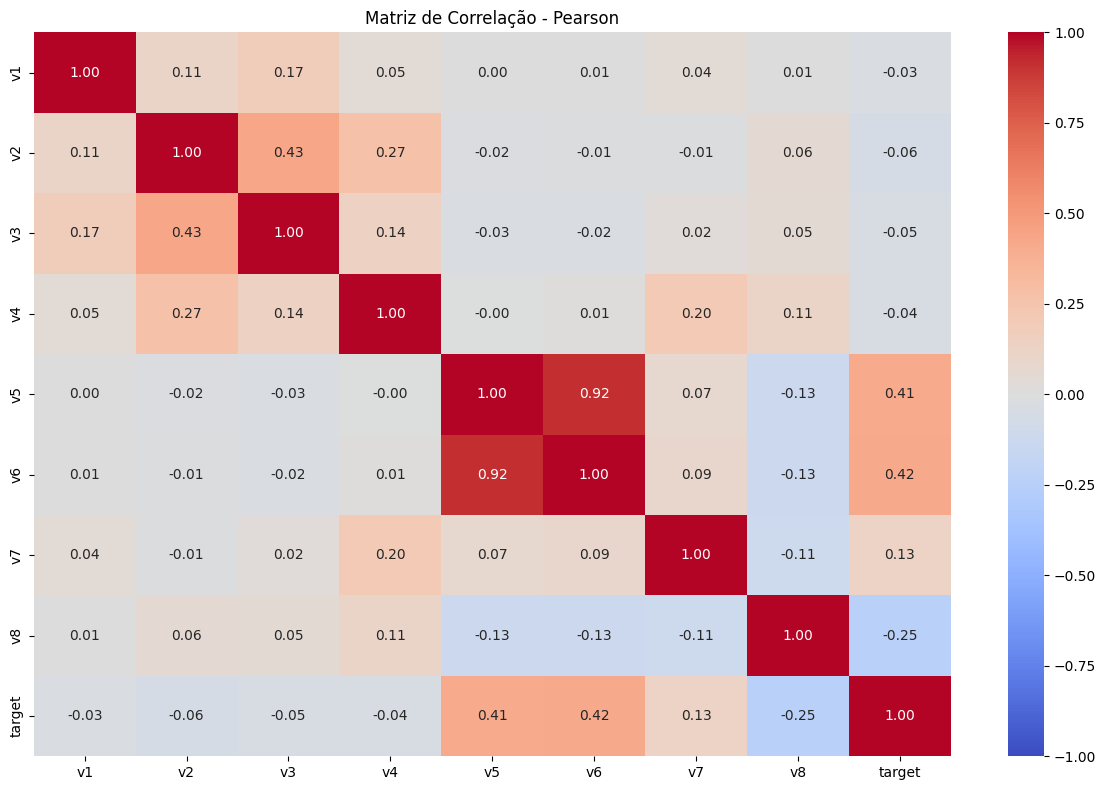

,Pearson,Spearman
v6,0.417559,0.426311
v5,0.409454,0.427012
v8,-0.245344,-0.249996
v7,0.127678,0.107484
v2,-0.061344,-0.057772
v3,-0.045962,-0.049832
v4,-0.039128,-0.026914
v1,-0.025413,-0.028588


In [6]:
from credit_risk.dataprep.selection import correlation_tables
from credit_risk.visualization.eda import plot_correlations
from credit_risk.visualization.rendering import show_plot

corr_pearson, correlacao_target = correlation_tables(df_treino, target=target)
show_plot(plot_correlations(corr_pearson))
display(correlacao_target)

A matriz de Pearson mostra que v6 e v5 têm as maiores correlações positivas com a target (0,42 e 0,41). Valores mais altos dessas variáveis tendem a estar associados à ocorrência do evento. Como a correlação entre elas é 0,93, há forte sobreposição de informação. Pelo critério de seleção do case, faz sentido manter v6, que apresenta associação ligeiramente maior com a target.

v8 se destaca no sentido oposto (−0,25). Valores mais altos tendem a estar associados a menor ocorrência do evento. Já v7 apresenta associação positiva fraca (0,13), e v1 a v4 têm correlações próximas de zero com a target. Essas variáveis ainda podem contribuir para o modelo por meio de relações não lineares ou interações.

,Pearson,Spearman
v6,0.417559,0.426311
v5,0.409454,0.427012
v8,-0.245344,-0.249996
v7,0.127678,0.107484
v2,-0.061344,-0.057772
v3,-0.045962,-0.049832
v4,-0.039128,-0.026914
v1,-0.025413,-0.028588


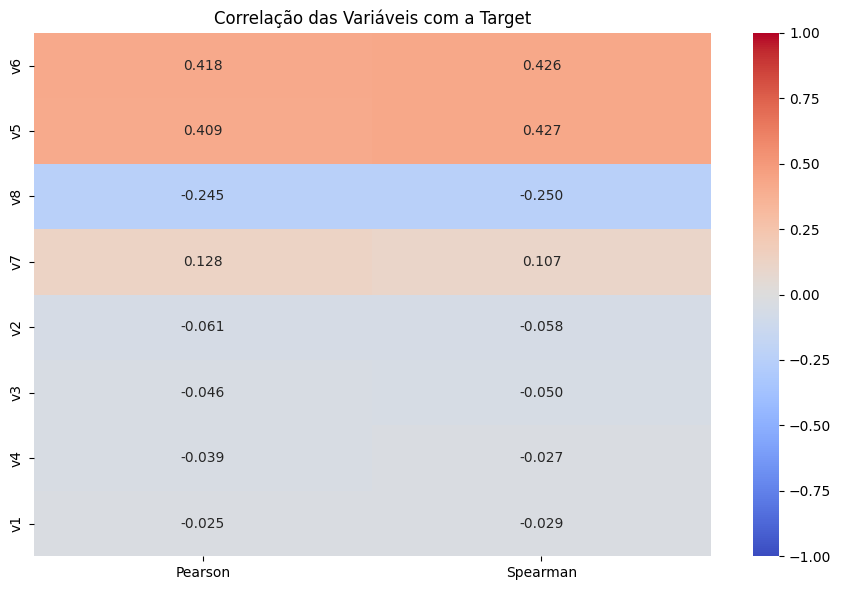

In [7]:
display(correlacao_target)
show_plot(plot_correlations(correlacao_target, by_target=True))

Pearson e Spearman apontam o mesmo padrão. As variáveis v6 e v5 apresentam as associações positivas mais fortes com a target. Em Pearson, v6 tem uma pequena vantagem (0,416 contra 0,407). Em Spearman, ambas chegam a 0,424 na precisão exibida. Considerando também a correlação de 0,93 entre elas na matriz anterior, o critério do case favorece manter v6.

v8 apresenta a associação negativa mais forte (−0,252 em Pearson e −0,258 em Spearman). Na amostra, valores maiores de v8 estão associados a menor ocorrência do evento. v7 tem associação positiva fraca, enquanto v1 a v4 têm correlações próximas de zero nos dois métodos. Avaliadas isoladamente, essas quatro variáveis mostram pouca associação linear ou monotônica com o evento.

## 5. Seleção de variáveis

O filtro prioriza o preditor com maior associação absoluta com a target. Ao observar uma correlação absoluta entre preditores ≥ 0,80, descarta o candidato que chega depois. A seleção agora é ajustada **exclusivamente no conjunto de treino**; o mesmo conjunto de preditores selecionados é aplicado ao teste, sem usar seus valores de target.

In [8]:
from credit_risk.dataprep.selection import select_features, show_selection

limite_corr = 0.80
# Selecionar variáveis somente a partir do treino (incluindo sua target).
df_filtrado, selecionadas, removidas = select_features(
    df_treino, target, threshold=limite_corr
)
show_selection(df_treino, df_filtrado, selecionadas, removidas)

# Aplicar a mesma seleção no treino e no teste, sem refazer o filtro no teste.
colunas_modelo = df_filtrado.columns.drop(target)
X_train = X_train_bruto.loc[:, colunas_modelo].copy()
X_test = X_test_bruto.loc[:, colunas_modelo].copy()

Variáveis selecionadas: ['v6', 'v8', 'v7', 'v2', 'v3', 'v4', 'v1']
Variáveis removidas: ['v5']
Dimensão original: (8000, 9)
Dimensão final: (8000, 8)


## 6. WoE monotônico e livre

Os dois discretizadores são ajustados no treino, limitados a cinco bins regulares por variável e com zero configurado como código especial. As tabelas permitem comparar o Information Value (IV) e examinar onde uma restrição monotônica muda os intervalos. Na referência, `v6` e `v8` têm os maiores IV nas duas alternativas.

In [9]:
from credit_risk.binning.woe import compare_iv, make_woe_transformer
from credit_risk.persistence.woe import save_woe

variaveis = X_train.columns.tolist()
binning_mono = make_woe_transformer(variaveis, trend="auto_asc_desc")
binning_livre = make_woe_transformer(variaveis, trend=None)
binning_mono.fit(X_train, y_train)
binning_livre.fit(X_train, y_train)

X_train_woe_mono = binning_mono.transform(X_train, metric="woe")
X_test_woe_mono = binning_mono.transform(X_test, metric="woe")
X_train_woe_livre = binning_livre.transform(X_train, metric="woe")
X_test_woe_livre = binning_livre.transform(X_test, metric="woe")

comparacao_iv = compare_iv(binning_mono, binning_livre)
display(comparacao_iv)
save_woe(
    paths.woe, monotonic=binning_mono, free=binning_livre,
    train_mono=X_train_woe_mono, test_mono=X_test_woe_mono,
    train_free=X_train_woe_livre, test_free=X_test_woe_livre,
    y_train=y_train, y_test=y_test, iv=comparacao_iv,
)

,name,IV_Monotonico,IV_Livre,Diferenca_IV
4,v6,0.947289,0.947772,0.000483
6,v8,0.806134,0.81082,0.004686
5,v7,0.285801,0.298019,0.012219
1,v2,0.066373,0.069507,0.003134
3,v4,0.043513,0.064226,0.020713
2,v3,0.031148,0.032379,0.001232
0,v1,0.008976,0.008976,0.0


v6 e v8 concentram o maior poder de separação entre eventos e não eventos no treino. Com WoE monotônico, os IVs são 0,9473 e 0,8061, respectivamente. Ao permitir faixas livres, os ganhos são pequenos (+0,0005 e +0,0047), indicando que a restrição de monotonicidade preserva quase toda a informação dessas duas variáveis.

v7 aparece em terceiro lugar (IV de 0,2858 a 0,2980), apesar da correlação de Pearson de apenas 0,130. Isso mostra que suas faixas distinguem perfis de risco melhor do que a correlação linear, isoladamente, sugere.

A v4 apresenta o maior ganho com o WoE livre (+0,0207), embora seu IV final permaneça baixo (0,0642). A v1 tem o menor IV nas duas abordagens (0,0090). No conjunto, a ordenação das variáveis é a mesma, o que favorece o uso do WoE monotônico na regressão logística pela facilidade de interpretar a evolução do risco entre faixas.

In [10]:
from credit_risk.binning.woe import binning_tables
from credit_risk.visualization.eda import show_binning_tables

show_binning_tables(binning_tables(variaveis, binning_mono, binning_livre))


VARIÁVEL: v6

MONOTÔNICO


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, inf)",368,0.046,98,270,0.733696,-3.05411,0.854040,0.078290
1,Special,7632,0.954,6982,650,0.085168,0.333463,0.093248,0.011602
2,Missing,0,0.000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,8000,1.000,7080,920,0.115000,,0.947289,0.089893



LIVRE


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 1839.45)",199,0.024875,55,144,0.723618,-3.003136,0.446727,0.041295
1,"[1839.45, inf)",169,0.021125,43,126,0.745562,-3.115737,0.407797,0.037006
2,Special,7632,0.954000,6982,650,0.085168,0.333463,0.093248,0.011602
3,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,8000,1.000000,7080,920,0.115000,,0.947772,0.089903



VARIÁVEL: v8

MONOTÔNICO


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 324.32)",353,0.044125,299,54,0.152975,-0.329196,0.005420,0.000674
1,"[324.32, 741.05)",692,0.086500,624,68,0.098266,0.175987,0.002503,0.000312
2,"[741.05, 1207.78)",895,0.111875,838,57,0.063687,0.647311,0.036512,0.004486
3,"[1207.78, 1383.18)",464,0.058000,444,20,0.043103,1.059437,0.043408,0.005186
4,"[1383.18, inf)",2476,0.309500,2415,61,0.024637,1.637925,0.450097,0.050712
5,Special,3120,0.390000,2460,660,0.211538,-0.724979,0.268194,0.032809
6,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,8000,1.000000,7080,920,0.115000,,0.806134,0.094179


... (18 outputs left out)


VARIÁVEL: v1

MONOTÔNICO


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, inf)",2006,0.25075,1808,198,0.098704,0.171054,0.006868,0.000857
1,Special,5994,0.74925,5272,722,0.120454,-0.052516,0.002108,0.000264
2,Missing,0,0.00000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,8000,1.00000,7080,920,0.115000,,0.008976,0.001121



LIVRE


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, inf)",2006,0.25075,1808,198,0.098704,0.171054,0.006868,0.000857
1,Special,5994,0.74925,5272,722,0.120454,-0.052516,0.002108,0.000264
2,Missing,0,0.00000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,8000,1.00000,7080,920,0.115000,,0.008976,0.001121


## 7. Regressão logística

O Logit do statsmodels recebe as variáveis em WoE monotônico e um intercepto. Os coeficientes estão na escala de log-odds por unidade de WoE. A tabela mostra estimativas, erros-padrão, intervalos e odds ratios. O p-valor de `v3` foi 0,3418 no ajuste histórico, e a variável permaneceu no modelo.


========== SUMMARY DO MODELO ==========


========== COEFICIENTES ==========



,Coeficiente,Erro_Padrao,P_Value,IC_95_Inferior,IC_95_Superior,Odds_Ratio,Significativo_5pct
const,-2.0060,0.0627,0.0000,-2.1288,-1.8832,0.1345,True
v6,-1.0317,0.0437,0.0000,-1.1172,-0.9461,0.3564,True
v8,-1.2652,0.0797,0.0000,-1.4214,-1.1091,0.2822,True
v7,-1.5392,0.2214,0.0000,-1.9730,-1.1053,0.2146,True
v2,-0.8053,0.1755,0.0000,-1.1492,-0.4614,0.4469,True
v3,-0.2333,0.2454,0.3418,-0.7144,0.2477,0.7919,False
v4,-0.8395,0.2291,0.0002,-1.2886,-0.3904,0.4319,True
v1,-1.3075,0.5846,0.0253,-2.4533,-0.1616,0.2705,True



========== MÉTRICAS DO MODELO ==========



,AUC,Gini,KS
Treino,0.8093,0.6187,0.4474
Teste,0.8255,0.6510,0.5019
Diferença,-0.0162,-0.0324,-0.0545


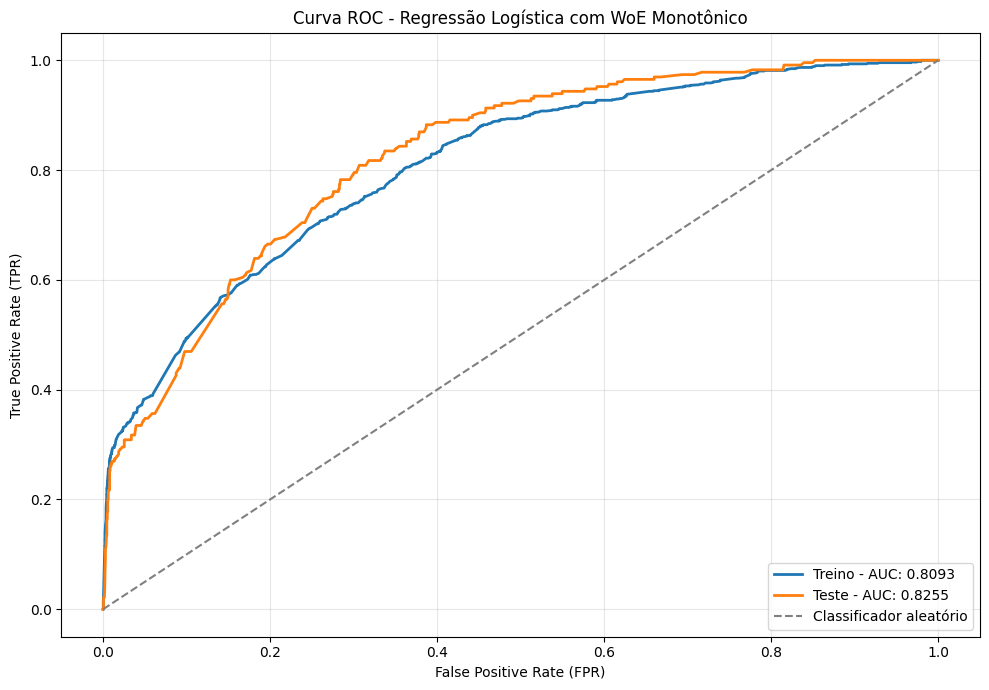

In [11]:
from credit_risk.modeling.logistic import (
    coefficient_table, fit_logistic, logistic_design, predict_logistic,
)
from credit_risk.evaluation.discrimination import roc_points, train_test_discrimination
from credit_risk.persistence.models import save_logistic
from credit_risk.visualization.modeling import plot_roc
from credit_risk.visualization.rendering import show_plot

resultado_lr = fit_logistic(X_train_woe_mono, y_train)
X_test_sm = logistic_design(X_test_woe_mono)
tabela_coeficientes = coefficient_table(resultado_lr)
print("\n========== SUMMARY DO MODELO ==========\n")
print("\n========== COEFICIENTES ==========\n")
display(tabela_coeficientes.round(4))

y_proba_train = predict_logistic(resultado_lr, X_train_woe_mono)
y_proba_test = predict_logistic(resultado_lr, X_test_woe_mono)
roc_lr_train = roc_points(y_train, y_proba_train)
roc_lr_test = roc_points(y_test, y_proba_test)
resultados = train_test_discrimination(roc_lr_train, roc_lr_test, "Diferença")
print("\n========== MÉTRICAS DO MODELO ==========\n")
display(resultados.round(4))
show_plot(plot_roc(roc_lr_train, roc_lr_test, logistic=True))
save_logistic(paths.logistic, resultado_lr)

### Interpretação da regressão logística

O modelo utiliza **WoE monotônico**. Cada coeficiente indica como as chances de evento variam quando o WoE de uma variável aumenta uma unidade, mantendo os demais preditores fixos. Neste projeto, um WoE maior indica maior presença relativa de não eventos.

#### Como ler a tabela de coeficientes

| Coluna | Interpretação |
| --- | --- |
| `Coeficiente` | Mudança no logaritmo das chances de evento por unidade de WoE. |
| `Erro_Padrao` | Incerteza associada à estimativa do coeficiente. |
| `P_Value` | P-valor do teste de que o coeficiente é zero. A exibição `0.0000` resulta do arredondamento. |
| `IC_95_Inferior` e `IC_95_Superior` | Limites do intervalo de confiança de 95% do coeficiente. |
| `Odds_Ratio` | Fator que multiplica as chances de evento a cada aumento de uma unidade de WoE. |
| `Significativo_5pct` | Indica se o p-valor é inferior a 0,05. |

#### Exemplo prático com a v6

A `v6` tem coeficiente **−1,0317** e *odds ratio* **0,3564**. Um aumento de uma unidade no WoE reduz as chances estimadas de evento em **64,36%**, mantendo as demais variáveis fixas. Aqui, *chances* correspondem a `PD / (1 − PD)`.

Para interpretar a variável original, é preciso observar como o transformador codificou cada grupo:

| Valor original de `v6` | WoE aplicado |
| --- | ---: |
| Igual a zero | 0 |
| Maior que zero | −3,054 |

Ao passar de zero para um valor positivo, o WoE **diminui**. Como o coeficiente também é negativo, o risco previsto **aumenta**. Para dois clientes iguais nas demais variáveis, aquele com `v6 > 0` tem chances estimadas de evento cerca de **23,4 vezes maiores** que aquele com `v6 = 0`.

#### Significância da v3

A `v3` é o único dos sete preditores com **p-valor acima de 0,05**. Seu p-valor é **0,3418**, e o intervalo de confiança de 95% vai de **−0,7144 a 0,2477**, incluindo zero. Assim, há pouca evidência de contribuição adicional de `v3` após considerar as demais variáveis do modelo.

#### Intercepto

A linha `const` representa o ponto de partida da regressão. Quando todos os preditores têm WoE igual a zero, a **PD estimada é de aproximadamente 11,9%**.

## 8. LightGBM e otimização de hiperparâmetros

A primeira prévia mostra o WoE livre. A segunda prepara as variáveis originais selecionadas que efetivamente alimentam a validação cruzada, o treinamento final e o SHAP.

In [12]:
from credit_risk.modeling.boosting import prepare_samples

# Prévia da matriz WoE livre examinada no notebook original.
X_treino_livre, X_teste_livre, alvo_treino_livre, alvo_teste_livre = prepare_samples(
    X_train_woe_livre, X_test_woe_livre, y_train, y_test
)
print("Treino:", X_treino_livre.shape)
print("Teste:", X_teste_livre.shape)
print("\nDistribuição da target:")
display(alvo_treino_livre.value_counts(normalize=True))

Treino: (8000, 7)
Teste: (2000, 7)

Distribuição da target:


0    0.885
1    0.115
Name: proportion, dtype: float64

In [13]:
# A busca, o modelo final e o SHAP usam os preditores originais selecionados.
X_train_lgb, X_test_lgb, y_train_lgb, y_test_lgb = prepare_samples(
    X_train, X_test, y_train, y_test
)
print("Treino:", X_train_lgb.shape)
print("Teste:", X_test_lgb.shape)
print("\nDistribuição da target:")
display(y_train_lgb.value_counts(normalize=True))

Treino: (8000, 7)
Teste: (2000, 7)

Distribuição da target:


0    0.885
1    0.115
Name: proportion, dtype: float64

O Hyperopt executa 40 tentativas de TPE. Cada tentativa usa três folds estratificados e early stopping de 50 rodadas. A menor log loss média seleciona a tentativa, e a mediana das melhores iterações dos folds define a quantidade final de árvores. O gráfico acompanha AUC ao longo da busca. Na execução histórica, a tentativa selecionada teve AUC média de 0,8134 e definiu 67 árvores.

In [14]:
from credit_risk.optimization.hyperopt_search import SearchConfig, optimize, search_space

config_busca = SearchConfig(seed=42, folds=3, max_evals=40, max_trees=1000, stopping_rounds=50)

In [15]:
espaco_busca = search_space()

Os valores quantizados de profundidade, folhas e tamanho mínimo de folha são convertidos para inteiros pela rotina de otimização.

In [16]:
busca = optimize(X_train_lgb, y_train_lgb, espaco_busca, config_busca)
best_params = busca.params
best_n_estimators = busca.n_estimators
melhor_trial = busca.best_trial
print("Melhores hiperparâmetros:")
print(best_params)
print("\nMelhor AUC CV:")
print(round(melhor_trial["auc_cv"], 4))
print("\nNúmero de árvores:")
print(best_n_estimators)

100%|██████████| 40/40 [00:09<00:00,  4.16trial/s, best loss: 0.2712537925858644] 
Melhores hiperparâmetros:
{'colsample_bytree': 0.6587166393316121, 'learning_rate': 0.14665415771798038, 'max_depth': 2, 'min_child_samples': 105, 'num_leaves': 4, 'reg_alpha': 0.673109023994718, 'reg_lambda': 0.012705188622752061, 'subsample': 0.833578215665429}

Melhor AUC CV:
0.8134

Número de árvores:
67


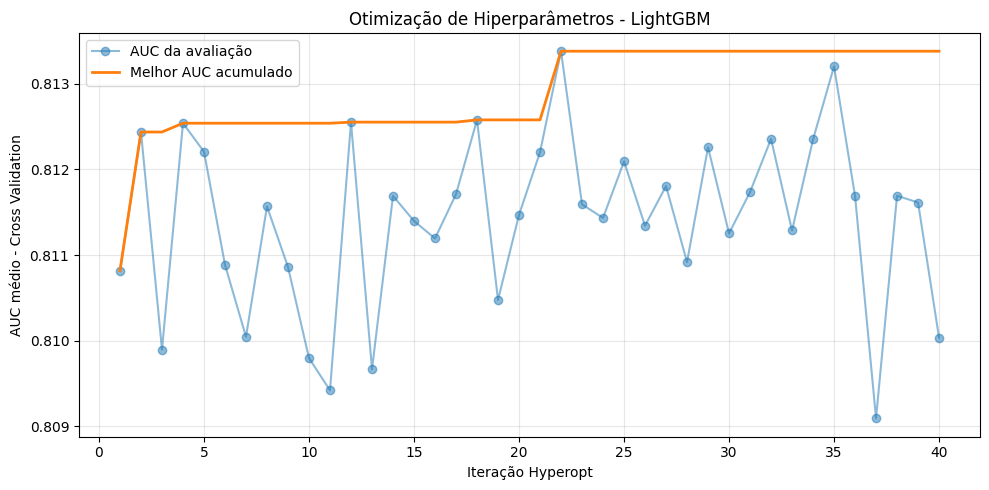

In [17]:
from credit_risk.visualization.modeling import plot_search_history

historico = busca.auc_history()
show_plot(plot_search_history(historico))

### Otimização dos hiperparâmetros do LightGBM

Nas 40 configurações avaliadas pelo Hyperopt, a AUC média de validação cruzada variou de aproximadamente **0,8091 a 0,8134**. A linha azul mostra a AUC de cada tentativa, enquanto a linha laranja registra a maior AUC obtida até aquele momento.

Na 4ª tentativa, a busca já havia alcançado uma AUC próxima de **0,8125**. O melhor resultado ocorreu na **22ª tentativa**, com **0,8134**, e permaneceu até o fim da busca. O ganho sobre a 4ª tentativa foi de aproximadamente **0,0009 de AUC**, indicando que as configurações posteriores trouxeram pouca melhora na capacidade de ordenar os clientes por risco.

Neste experimento, o critério de seleção do modelo foi a **menor log loss média** na validação cruzada. O gráfico acompanha a discriminação pela AUC, e a configuração selecionada pela log loss também atingiu AUC de **0,8134**.

In [18]:
from credit_risk.modeling.boosting import predict_pd, train_lightgbm

modelo_lgb = train_lightgbm(
    X_train_lgb, y_train_lgb, best_params, best_n_estimators, seed=config_busca.seed,
    n_jobs=config_busca.n_jobs,
)
y_proba_train_lgb = predict_pd(modelo_lgb, X_train_lgb)
y_proba_test_lgb = predict_pd(modelo_lgb, X_test_lgb)
print("LightGBM treinado com sucesso!")

LightGBM treinado com sucesso!


## 9. Discriminação e calibração

AUC, Gini e KS medem ordenação. Brier e log loss avaliam a qualidade das probabilidades. As curvas de calibração agrupam por quantis. Nas tabelas por decil, o desempate de PD usa a ordem das observações. A coluna de diferença é a PD média menos a taxa observada, em pontos percentuais.

In [19]:
roc_lgb_train = roc_points(y_train_lgb, y_proba_train_lgb)
roc_lgb_test = roc_points(y_test_lgb, y_proba_test_lgb)
resultados_lgb = train_test_discrimination(roc_lgb_train, roc_lgb_test, "Gap")
display(resultados_lgb.round(4))

,AUC,Gini,KS
Treino,0.8321,0.6641,0.5114
Teste,0.8434,0.6868,0.5476
Gap,-0.0113,-0.0226,-0.0362


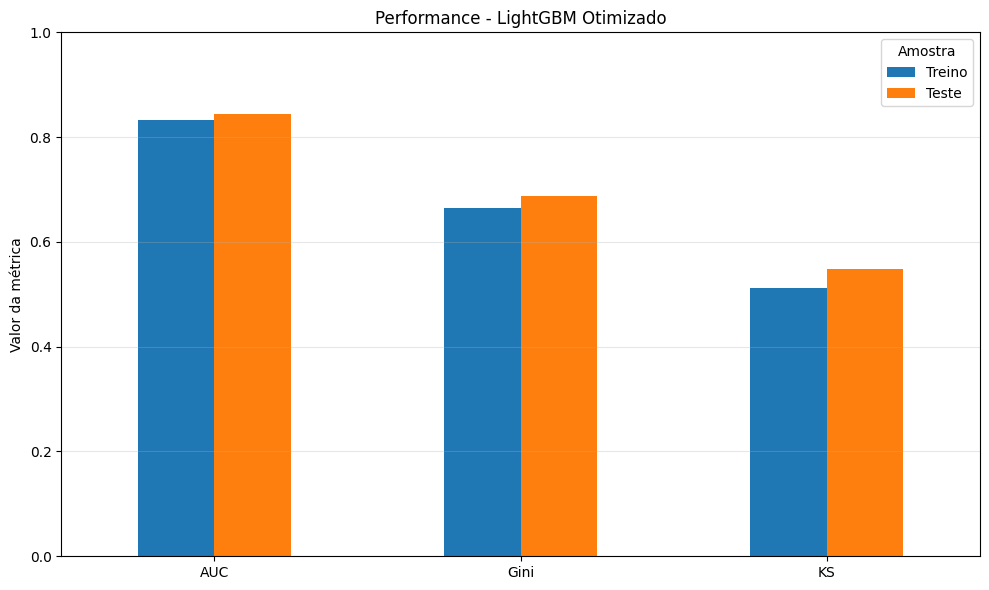

In [20]:
from credit_risk.visualization.modeling import plot_discrimination

show_plot(plot_discrimination(resultados_lgb))

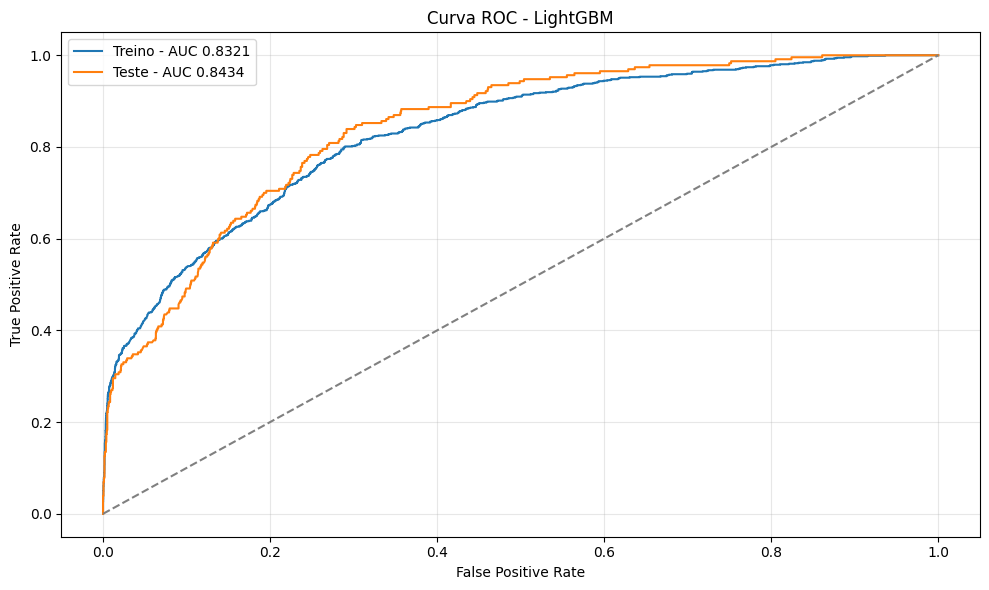

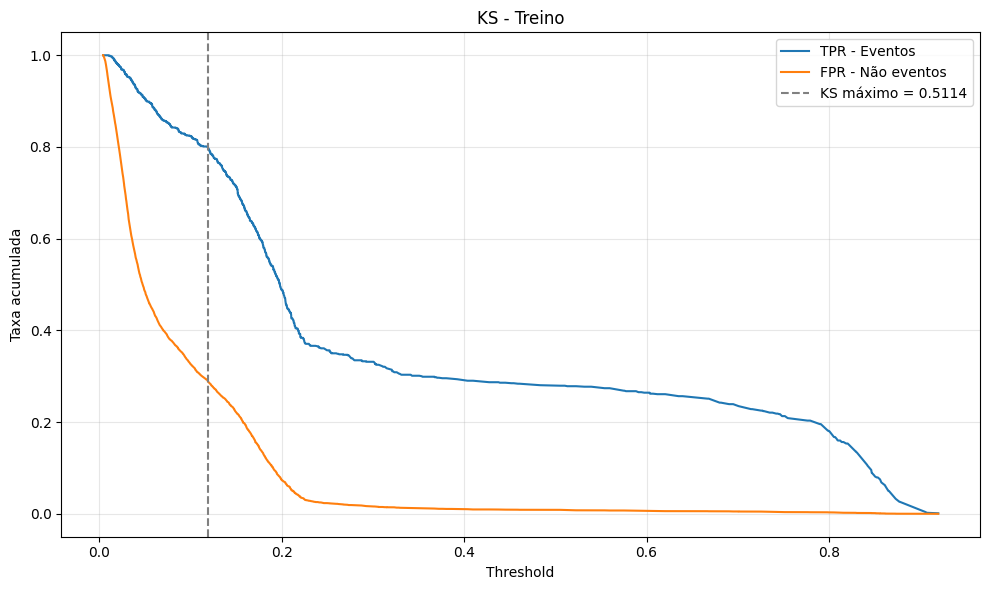

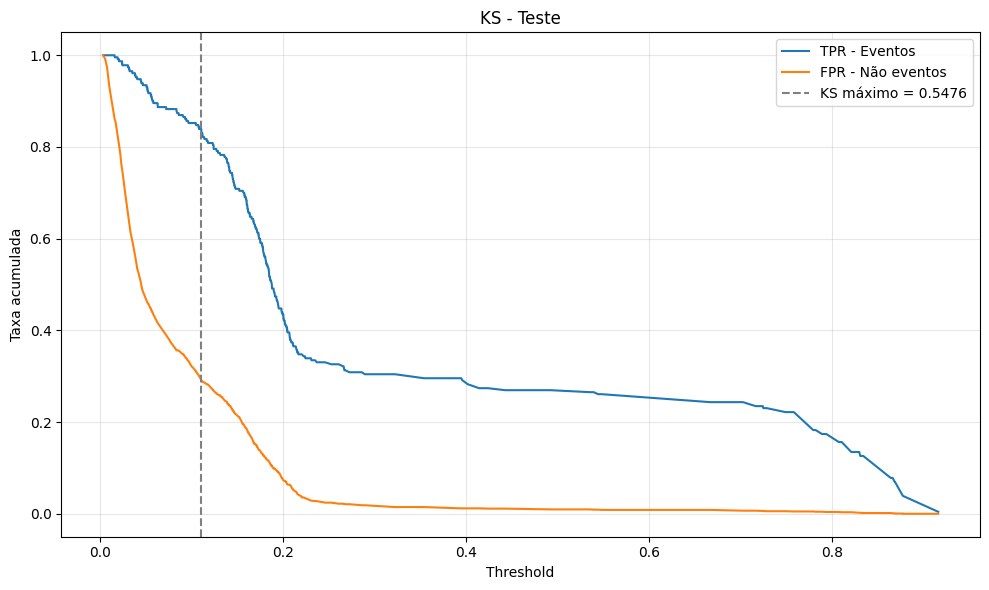

In [21]:
from credit_risk.visualization.modeling import plot_ks

show_plot(plot_roc(roc_lgb_train, roc_lgb_test, logistic=False))
show_plot(plot_ks(roc_lgb_train, "KS - Treino"))
show_plot(plot_ks(roc_lgb_test, "KS - Teste"))

### Discriminação do LightGBM — curvas ROC e KS

**Curva ROC.** Cada ponto representa um possível corte de PD para classificar um cliente como alto risco. O eixo horizontal mostra a proporção de não eventos classificados como alto risco (falsos positivos). O eixo vertical mostra a proporção de eventos capturados (verdadeiros positivos). Quanto mais próxima do canto superior esquerdo, melhor a curva.

A AUC foi de **0,8321 no treino** e **0,8434 no teste**. Na prática, ao escolher ao acaso um cliente com evento e outro sem evento na base de teste, o modelo atribui maior risco ao cliente com evento em aproximadamente **84,3%** das comparações, contando empates pela metade.

**Curvas KS.** A linha azul mostra a proporção de eventos com PD igual ou superior a cada corte. A laranja mostra a mesma proporção entre os não eventos. A linha vertical tracejada marca o corte em que a distância entre essas duas proporções é máxima. O KS atingiu **51,14 pontos percentuais no treino** e **54,76 pontos percentuais no teste**.

**Leitura prática.** No teste, o KS máximo ocorre em um corte de PD próximo de **11%**. Nesse ponto, o modelo sinaliza como alto risco aproximadamente **84 de cada 100 clientes com evento** e **29 de cada 100 clientes sem evento**. A diferença entre essas taxas corresponde ao KS de cerca de 55 pontos percentuais.

As duas métricas ficaram ligeiramente maiores no teste, indicando que o modelo preservou sua capacidade de ordenação nessa amostra. Para definir um corte de decisão de crédito, é preciso considerar também o custo de deixar passar um evento e o de restringir um cliente que pagaria em dia.

### Calibração da regressão logística

,Taxa_Evento,PD_Media,Brier_Score,Log_Loss
Treino,0.115,0.1150,0.0771,0.2727
Teste,0.115,0.1153,0.0783,0.2700


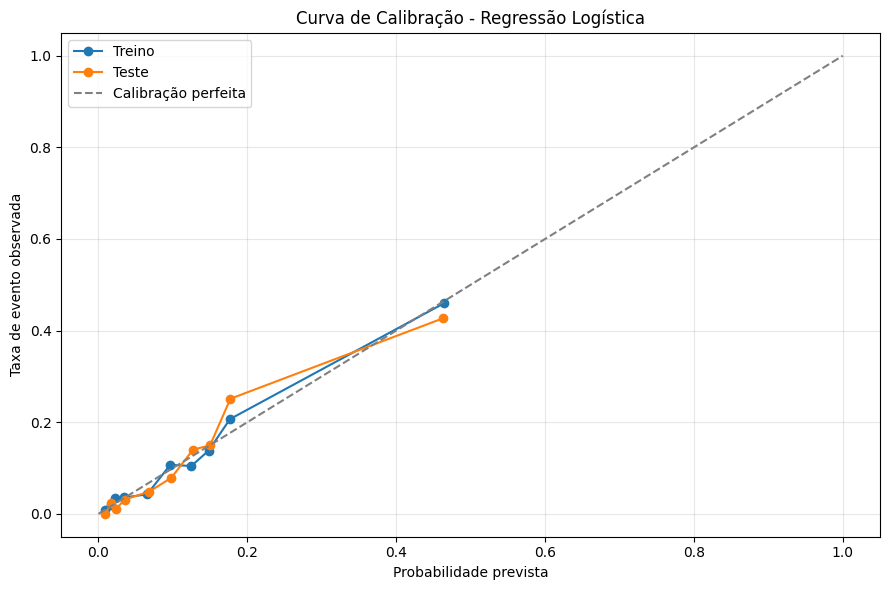

In [22]:
from credit_risk.evaluation.calibration import calibration_curves, calibration_summary
from credit_risk.visualization.comparison import plot_calibration

resultados_calibracao = calibration_summary(y_train, y_proba_train, y_test, y_proba_test)
display(resultados_calibracao.round(4))
curvas_lr = calibration_curves(y_train, y_proba_train, y_test, y_proba_test)
show_plot(plot_calibration(curvas_lr, "Curva de Calibração - Regressão Logística"))

### Calibração da regressão logística

**Na carteira como um todo, a PD média ficou muito próxima da taxa de eventos observada.** No teste, o modelo estimou uma PD média de **11,53%**, frente a **11,50%** de eventos, uma diferença de apenas **0,03 ponto percentual**. No treino, ambas foram de **11,50%**. Essa proximidade no treino é esperada em uma regressão logística ajustada com intercepto.

**Como ler a curva.** Cada ponto representa um grupo de clientes com probabilidades previstas semelhantes. O eixo horizontal mostra a PD média prevista para o grupo, e o vertical mostra a taxa de eventos observada. Pontos acima da diagonal indicam que o modelo **subestimou o risco**. Pontos abaixo indicam que **superestimou o risco**.

Na curva de teste, dois grupos ilustram por que vale olhar além da média da carteira:

- No grupo com **PD prevista próxima de 18%**, a taxa observada foi de aproximadamente **25%**. O modelo subestimou o risco em cerca de **7 pontos percentuais**.
- No grupo de maior risco, a **PD prevista ficou em torno de 46%**, enquanto a taxa observada ficou próxima de **43%**. Nesse grupo, o modelo superestimou o risco em cerca de **3 pontos percentuais**.

**Brier Score e Log Loss.** As duas métricas avaliam a qualidade das probabilidades, e valores menores são melhores. O Brier passou de **0,0771 no treino para 0,0783 no teste**, enquanto a Log Loss passou de **0,2727 para 0,2700**. Como referência, atribuir a mesma PD de 11,50% a todos os clientes produziria um Brier de aproximadamente **0,1018** no teste.

**Conclusão:** a regressão logística reproduziu bem o risco médio da carteira de teste. O principal desvio visível ocorreu no grupo com PD próxima de 18%, onde a frequência de eventos superou a previsão. A superestimação em outras faixas ajuda a explicar por que esse desvio quase desaparece na média geral.

In [23]:
from credit_risk.evaluation.calibration import calibration_deciles

tabela_decil = calibration_deciles(y_test, y_proba_test)
display(tabela_decil.round(4))

,Clientes,Eventos,PD_Media,Taxa_Observada,Diferenca_pp
Decil,,,,,
1,200,0,0.0090,0.000,0.9043
2,200,4,0.0169,0.020,-0.3063
3,200,3,0.0229,0.015,0.7911
4,200,6,0.0348,0.030,0.4752
5,200,9,0.0671,0.045,2.2110
6,200,16,0.0972,0.080,1.7214
7,200,28,0.1265,0.140,-1.3508
8,200,29,0.1495,0.145,0.4524
9,200,51,0.1768,0.255,-7.8159


### Calibração do LightGBM

A razão O/E divide a taxa observada pela PD média. A regressão de calibração sobre o logit da PD estima intercepto e inclinação no teste. Os valores ideais são zero e um, respectivamente. O diagnóstico usa as probabilidades originais dos modelos.

In [24]:
from credit_risk.evaluation.calibration import calibration_summary

resultados_calibracao_lgb = calibration_summary(
    y_train_lgb, y_proba_train_lgb, y_test_lgb, y_proba_test_lgb, extended=True,
)
display(resultados_calibracao_lgb.round(4))

,Taxa_Evento,PD_Media,O_E,Brier_Score,Log_Loss,AUC
Treino,0.115,0.1142,1.0068,0.0746,0.2617,0.8321
Teste,0.115,0.1136,1.0127,0.0758,0.2603,0.8434


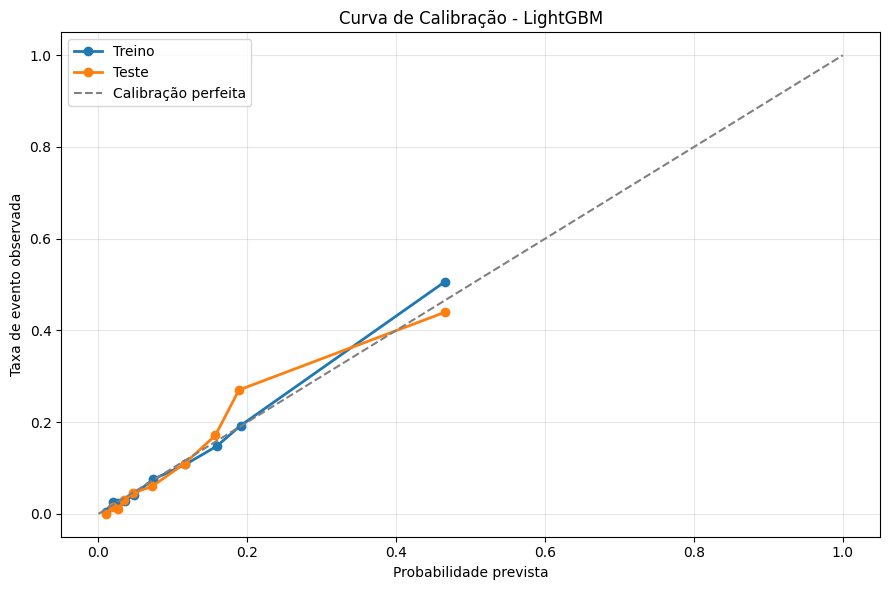

In [25]:
from credit_risk.evaluation.calibration import calibration_curves
from credit_risk.visualization.comparison import plot_calibration

curvas_lgb = calibration_curves(y_train_lgb, y_proba_train_lgb, y_test_lgb, y_proba_test_lgb)
show_plot(plot_calibration(curvas_lgb, "Curva de Calibração - LightGBM", linewidth=2))

### Calibração do LightGBM

O LightGBM apresentou previsões próximas das taxas observadas nas faixas de menor risco. **O maior desvio visível no teste ocorreu no grupo com PD média próxima de 19%**, em que a taxa de eventos chegou a aproximadamente **27%**.

Cada ponto representa um grupo de clientes. O eixo horizontal mostra a **PD média prevista**, e o vertical mostra a **taxa de eventos observada**. Na diagonal tracejada, os dois valores coincidem. Acima dela, o modelo subestima o risco do grupo. Abaixo, superestima.

| Faixa na amostra de teste | PD média prevista | Taxa observada | Interpretação |
|---|---:|---:|---|
| Grupo com PD próxima de 19% | 18,9% | 27,0% | Subestimação de aproximadamente **8,1 pontos percentuais**. |
| Grupo de maior risco | 46,6% | 44,0% | Superestimação de aproximadamente **2,6 pontos percentuais**. |

Na carteira de teste como um todo, a PD média foi de **11,36%**, próxima dos **11,50%** de eventos observados. Essa média esconde desvios em sentidos opostos. Em termos práticos, **a cada 100 clientes do grupo com PD próxima de 19%, o modelo estimou cerca de 19 eventos e foram observados 27**. Essa é a faixa que merece maior atenção ao avaliar a calibração em outra safra.

In [26]:
from credit_risk.evaluation.calibration import calibration_deciles

tabela_decil_lgb = calibration_deciles(y_test_lgb, y_proba_test_lgb, extended=True)
display(tabela_decil_lgb.round(4))

,Clientes,Eventos,PD_Media,Taxa_Observada,Diferenca_pp,O_E
Decil,,,,,,
1,200,0,0.0099,0.000,0.9862,0.0000
2,200,3,0.0189,0.015,0.3928,0.7925
3,200,2,0.0266,0.010,1.6640,0.3754
4,200,6,0.0345,0.030,0.4528,0.8689
5,200,9,0.0462,0.045,0.1216,0.9737
6,200,12,0.0721,0.060,1.2132,0.8318
7,200,22,0.1155,0.110,0.5514,0.9523
8,200,34,0.1569,0.170,-1.3096,1.0835
9,200,54,0.1887,0.270,-8.1280,1.4307


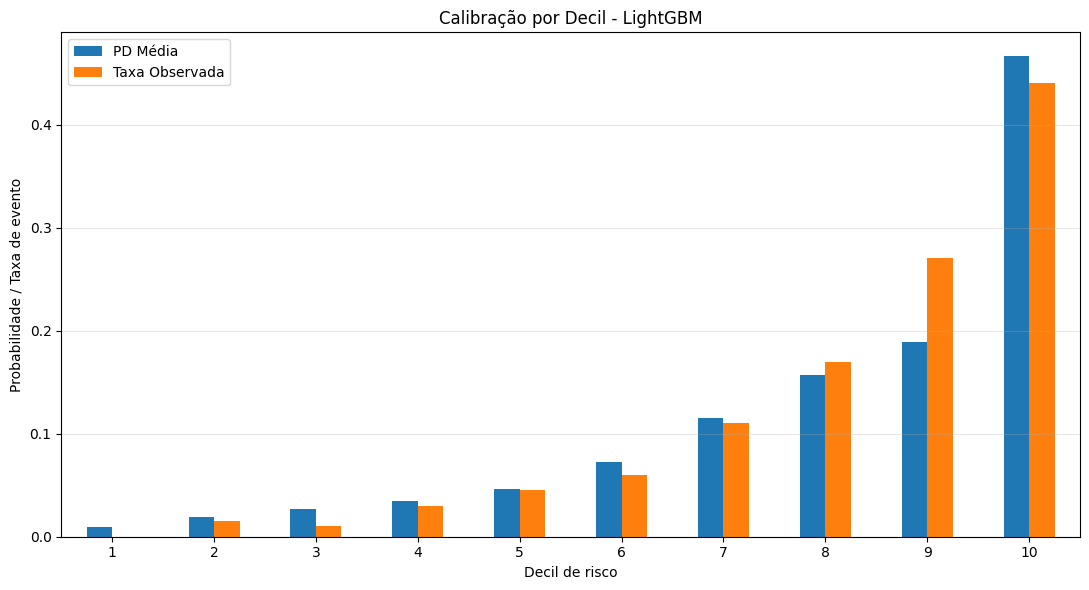

In [27]:
from credit_risk.visualization.comparison import plot_calibration_deciles

show_plot(plot_calibration_deciles(tabela_decil_lgb))

### Calibração por decil de risco — LightGBM

Os 2.000 clientes do teste foram ordenados pela PD prevista e divididos em **10 grupos de 200 clientes**, do menor risco (decil 1) ao maior (decil 10). A barra azul representa a **PD média prevista**, e a laranja, a **taxa de eventos observada**. Quanto mais próximas as barras de um mesmo decil, melhor a calibração naquela faixa.

- **Decis 1 a 8:** as diferenças entre a PD média e a taxa observada ficaram abaixo de 2 pontos percentuais em cada grupo. No decil 1, por exemplo, a PD média foi de aproximadamente 1% e nenhum dos 200 clientes apresentou o evento.
- **Decil 9:** apresentou o maior desvio. A PD média foi de **18,9%**, mas a taxa observada chegou a **27,0%**. Isso corresponde a cerca de **38 eventos esperados e 54 observados**, uma subestimação de **8,1 pontos percentuais**.
- **Decil 10:** a PD média foi de **46,6%**, frente a **44,0%** de eventos observados. Nesse grupo, o modelo superestimou o risco em **2,6 pontos percentuais**, com cerca de **93 eventos esperados e 88 observados**.

**Conclusão.** O LightGBM concentrou **142 dos 230 eventos (61,7%) nos 20% de clientes com maior PD**, o que evidencia sua capacidade de ordenar o risco. Para estimar o volume de eventos por faixa, o principal ponto de atenção é o **decil 9**, onde ocorreram cerca de 16 eventos a mais do que o previsto.

In [28]:
from credit_risk.evaluation.calibration import calibration_regression

tabela_calibracao = calibration_regression(y_test_lgb, y_proba_test_lgb)
display(tabela_calibracao.round(4))

,Parametro,Estimativa,IC_95_Inferior,IC_95_Superior,Valor_Ideal
0,Intercept,0.1754,-0.1171,0.4679,0
1,Slope,1.0902,0.9489,1.2316,1


## 10. Comparação estatística entre os modelos

A comparação usa o mesmo cliente e a mesma realização do evento nos dois modelos. O bootstrap pareado sorteia eventos e não eventos separadamente e mantém o emparelhamento das predições. O intervalo percentil resume a diferença de Gini do LightGBM em relação ao Logit nesta amostra de teste.

In [29]:
from credit_risk.evaluation.comparison import compare_predictions

y_true = y_test
proba_lr = y_proba_test
proba_lgb = y_proba_test_lgb
previsoes_teste = {"Regressão Logística": proba_lr, "LightGBM": proba_lgb}
comparacao_modelos = compare_predictions(y_true, previsoes_teste)
display(comparacao_modelos.round(4))

,AUC,Gini,KS,Log_Loss,Brier_Score,PD_Media,O_E
Regressão Logística,0.8255,0.6510,0.5019,0.2700,0.0783,0.1153,0.9974
LightGBM,0.8434,0.6868,0.5476,0.2603,0.0758,0.1136,1.0127


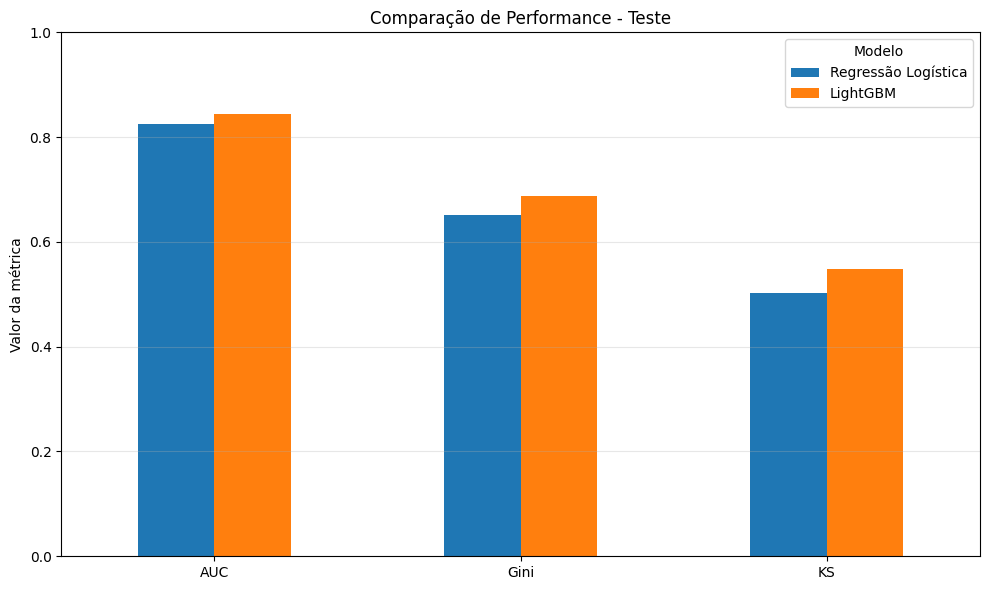

In [30]:
from credit_risk.visualization.comparison import plot_discrimination_comparison

show_plot(plot_discrimination_comparison(comparacao_modelos))

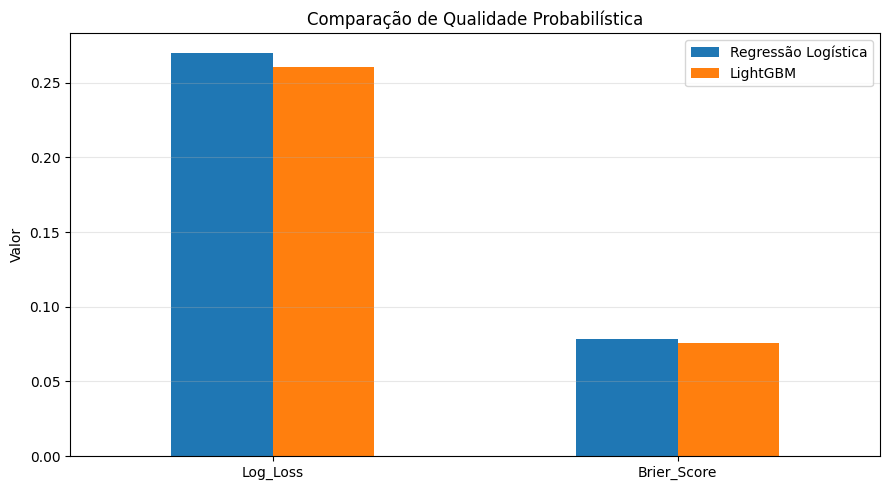

In [31]:
from credit_risk.visualization.comparison import plot_quality_comparison

show_plot(plot_quality_comparison(comparacao_modelos))

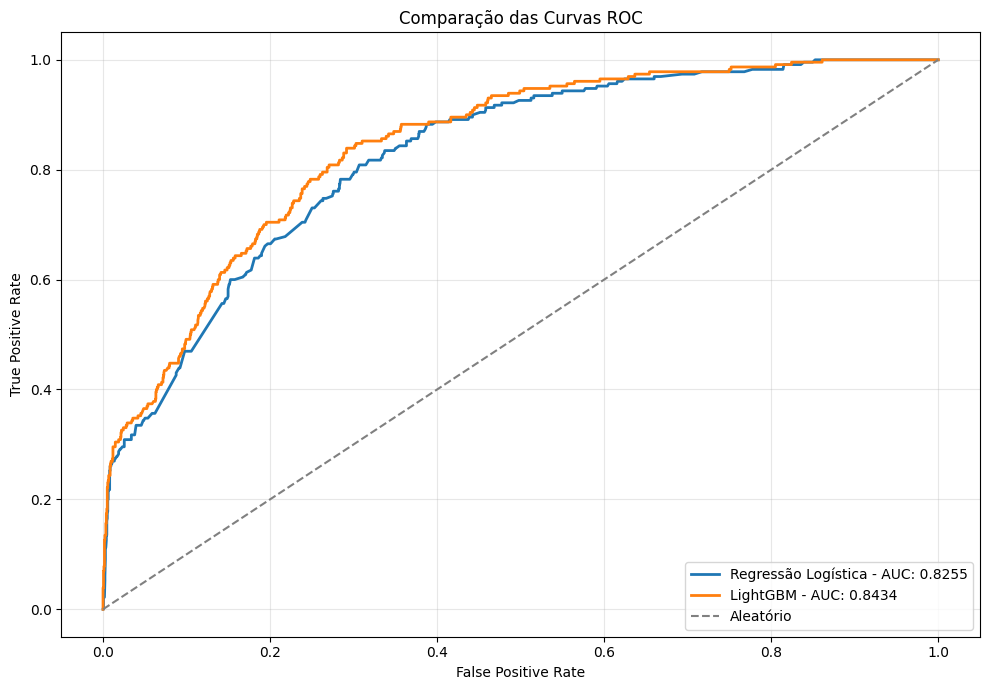

In [32]:
from credit_risk.evaluation.comparison import comparison_roc
from credit_risk.visualization.comparison import plot_test_roc

curvas_roc_teste = comparison_roc(y_true, previsoes_teste)
show_plot(plot_test_roc(curvas_roc_teste))

### Comparação dos modelos na base de teste

O **LightGBM** apresentou melhor desempenho nos mesmos 2.000 clientes de teste. Ele ordenou melhor os clientes por risco e obteve menor erro nas probabilidades previstas.

| Métrica | Regressão logística | LightGBM | Melhor resultado |
|---|---:|---:|---|
| AUC | 0,8255 | **0,8434** | Maior |
| Gini | 0,6510 | **0,6868** | Maior |
| KS | 0,5019 | **0,5476** | Maior |
| Log Loss | 0,2700 | **0,2603** | Menor |
| Brier Score | 0,0783 | **0,0758** | Menor |

**Discriminação.** Ao comparar um cliente que apresentou o evento com outro que não apresentou, o LightGBM atribuiu maior risco ao primeiro em aproximadamente **84,3%** dos pares, contra **82,6%** na regressão logística, contando empates pela metade. O Gini expressa essa mesma ordenação em outra escala. Pelo KS, a maior separação entre as distribuições de eventos e não eventos passou de **50,19 para 54,76 pontos percentuais**.

**Qualidade das probabilidades.** O Brier Score menor indica que as PDs do LightGBM ficaram, em média, mais próximas dos desfechos observados segundo o erro quadrático. A Log Loss também caiu. Essa métrica penaliza especialmente previsões muito confiantes que se revelam erradas.

**Conclusão para o case.** Os resultados favorecem o **LightGBM** para a construção da régua de risco. A vantagem aparece tanto na ordenação dos clientes quanto na qualidade global das PDs. A principal ressalva é a calibração do **9º decil**: nessa faixa, a PD média foi de **18,9%**, enquanto a taxa observada chegou a **27,0%**.

Diferença observada de Gini: 0.0357
IC 95% Bootstrap: [0.0128, 0.0589]


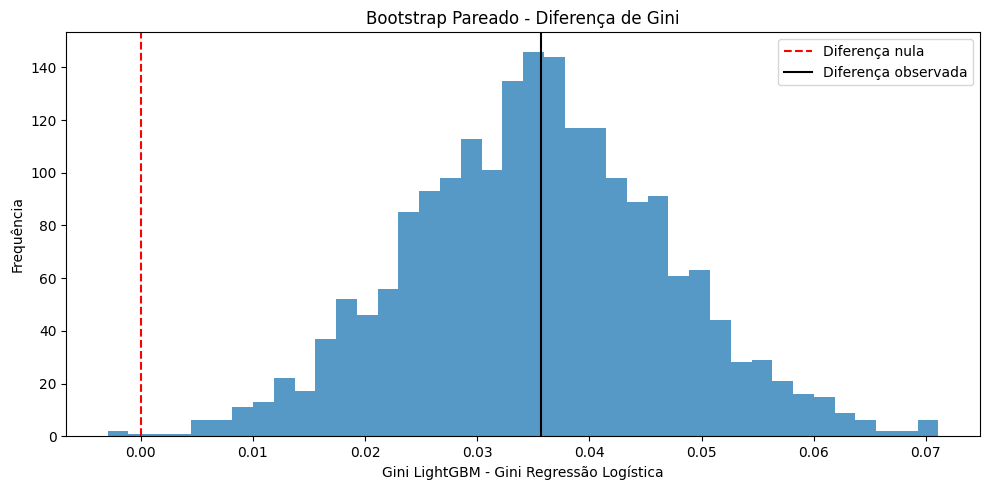

In [33]:
from credit_risk.evaluation.bootstrap import paired_gini_bootstrap
from credit_risk.visualization.comparison import plot_bootstrap

bootstrap = paired_gini_bootstrap(y_true, proba_lr, proba_lgb, n_resamples=2000, seed=42)
print(f"Diferença observada de Gini: {bootstrap.observed:.4f}")
print(f"IC 95% Bootstrap: [{bootstrap.lower:.4f}, {bootstrap.upper:.4f}]")
show_plot(plot_bootstrap(bootstrap))

### Bootstrap pareado — diferença de Gini entre os modelos

O LightGBM apresentou **ganho de 3,57 pontos de Gini** sobre a regressão logística na base de teste. O intervalo de confiança de 95% para esse ganho foi de **1,28 a 5,89 pontos**. Como o intervalo ficou inteiramente acima de zero, há evidência estatística de que o LightGBM ordena melhor os clientes por risco na população representada pelo teste.

**Como ler o gráfico.** O eixo horizontal mostra a diferença `Gini do LightGBM − Gini da regressão logística`. A linha vermelha em zero representa um empate, e a linha preta marca a diferença observada de **0,0357**. As barras mostram a frequência das diferenças obtidas em **2.000 reamostragens** da base de teste. Em cada uma, os dois modelos foram avaliados nos mesmos clientes sorteados, preservando o pareamento das previsões.

**Interpretação para o case.** A vantagem do LightGBM se manteve na grande maioria das reamostragens. O intervalo quantifica a incerteza do ganho de discriminação para os modelos já treinados. A persistência desse ganho em safras futuras exige validação temporal.

## 11. PSI, HHI e estabilidade

O PSI compara as frequências das categorias WoE no treino e no teste. Na referência, todas as variáveis ficaram abaixo de 0,10 nas duas transformações. Essa comparação foi feita em um split aleatório da mesma base. Uma avaliação temporal exigiria outra safra.

In [34]:
from credit_risk.binning.stability import classify_psi_table, compare_psi

In [35]:
df_psi = compare_psi(
    X_train_woe_mono, X_test_woe_mono, X_train_woe_livre, X_test_woe_livre
)
display(df_psi.round(5))

,Variavel,PSI_Monotonico,PSI_Livre,Diferenca
5,v4,0.00696,0.00687,-0.00009
4,v3,0.00015,0.00329,0.00314
3,v2,0.00199,0.00310,0.00111
2,v7,0.00215,0.00217,0.00002
1,v8,0.00084,0.00201,0.00117
0,v6,0.00002,0.00127,0.00124
6,v1,0.00004,0.00004,0.00000


In [36]:
df_psi = classify_psi_table(df_psi)
display(df_psi.round(5))

,Variavel,PSI_Monotonico,PSI_Livre,Diferenca,Status_Monotonico,Status_Livre
5,v4,0.00696,0.00687,-0.00009,Baixa mudança,Baixa mudança
4,v3,0.00015,0.00329,0.00314,Baixa mudança,Baixa mudança
3,v2,0.00199,0.00310,0.00111,Baixa mudança,Baixa mudança
2,v7,0.00215,0.00217,0.00002,Baixa mudança,Baixa mudança
1,v8,0.00084,0.00201,0.00117,Baixa mudança,Baixa mudança
0,v6,0.00002,0.00127,0.00124,Baixa mudança,Baixa mudança
6,v1,0.00004,0.00004,0.00000,Baixa mudança,Baixa mudança


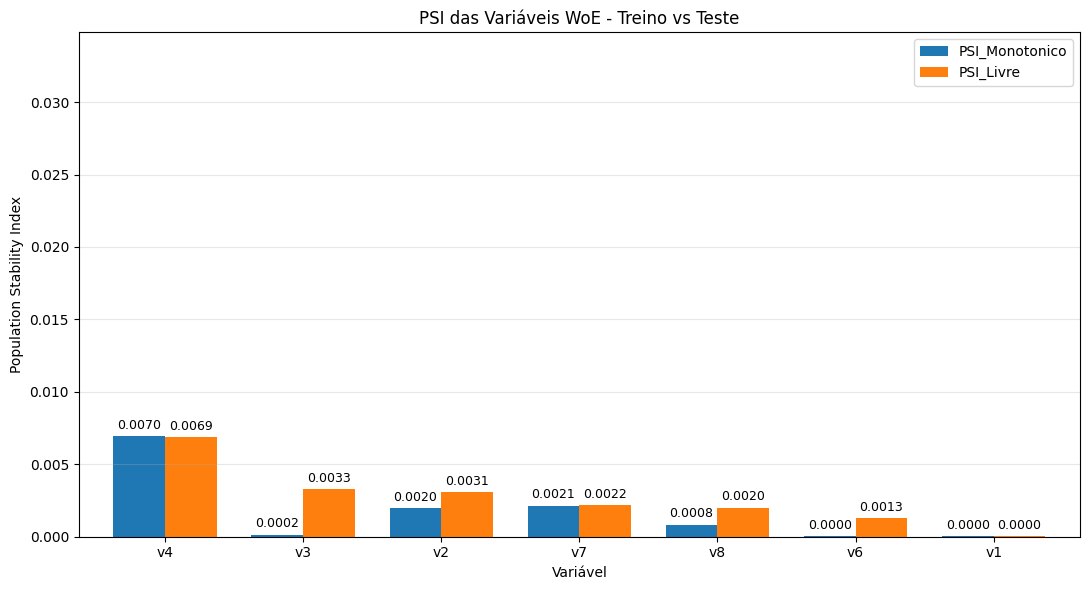

In [37]:
from credit_risk.visualization.eda import plot_psi

show_plot(plot_psi(df_psi))

### Estabilidade das variáveis WoE entre treino e teste

As sete variáveis apresentaram **PSI igual ou inferior a 0,0070** nas duas transformações WoE, bem abaixo do limite de **0,10** adotado no projeto. Isso indica que a proporção de clientes em cada faixa de WoE foi semelhante no treino e no teste. Quanto mais próximo de zero o PSI, menor a mudança nessa distribuição.

A **v4** apresentou a maior diferença entre as amostras, com PSI de **0,0070** no WoE monotônico e **0,0069** no livre. Já a **v3** apresentou a maior diferença entre os métodos: **0,0002** no monotônico e **0,0033** no livre. Nesse caso, a divisão livre revelou uma pequena variação na ocupação das faixas, ainda classificada como baixa.

A **v6** ilustra como interpretar o índice. No WoE monotônico, a proporção de clientes com valor positivo passou de **4,60% no treino para 4,50% no teste**. Como essa transformação separa os clientes em zero e positivo, a pequena diferença explica o PSI exibido como **0,0000** após arredondamento.

**Conclusão.** Pelo critério de estabilidade, as duas transformações tiveram resultados semelhantes neste split. Como treino e teste vieram de uma divisão aleatória da mesma base, a estabilidade ao longo do tempo precisa ser avaliada em safras posteriores, aplicando os mesmos cortes aprendidos no treino.

### Concentração de eventos e de clientes

O HHI de eventos usa a participação dos eventos em cada decil de risco. O HHI de carteira usa participações de clientes em faixas fixas de PD. Essas duas tabelas respondem a perguntas diferentes sobre concentração.

In [38]:
from credit_risk.evaluation.concentration import event_concentration

comparacao_hhi, comparacao_eventos = event_concentration(y_true, previsoes_teste)
display(comparacao_hhi.round(4))

,Modelo,HHI_Eventos
0,Regressão Logística,0.2208
1,LightGBM,0.2377


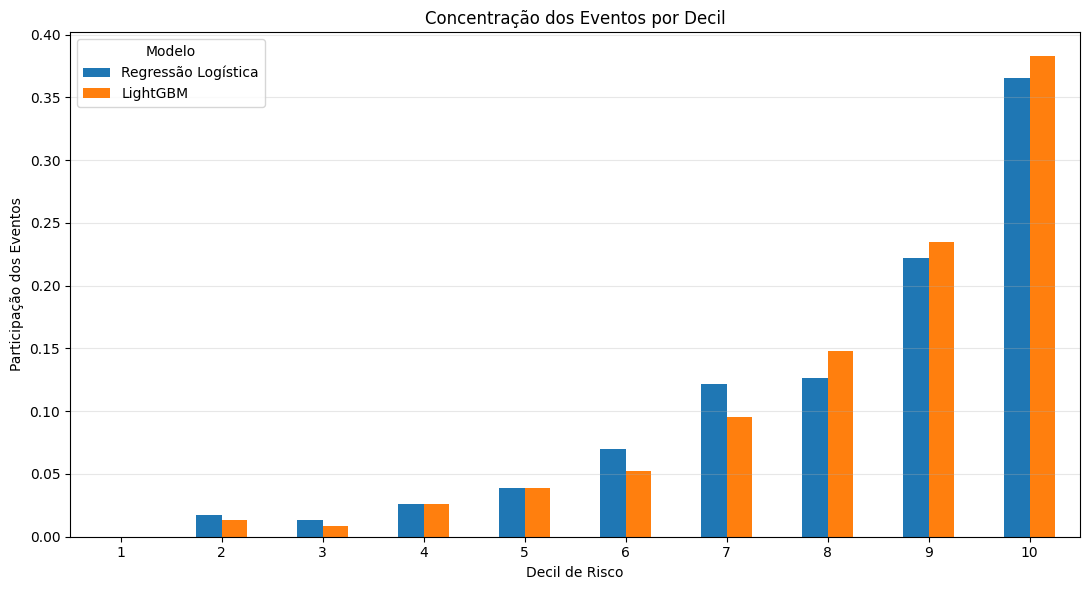

In [39]:
from credit_risk.visualization.comparison import plot_event_shares

show_plot(plot_event_shares(comparacao_eventos))

### Concentração dos eventos por decil de risco

O **LightGBM concentrou 61,7% dos eventos nos 20% de clientes com maior risco previsto**, enquanto a regressão logística concentrou **58,7%**. Na base de teste, isso equivale a identificar **7 eventos a mais** ao selecionar a mesma quantidade de clientes.

Cada modelo ordena os 2.000 clientes pela sua própria PD e os divide em dez grupos de 200. O decil 1 reúne os clientes de menor risco previsto e o decil 10, os de maior risco. A altura de cada barra representa a **participação do decil nos 230 eventos observados**. Para cada modelo, as dez barras somam 100%.

| Faixa selecionada | Regressão logística | LightGBM |
|---|---:|---:|
| 10% de maior risco — decil 10 | 84 eventos (36,5%) | **88 eventos (38,3%)** |
| 20% de maior risco — decis 9 e 10 | 135 eventos (58,7%) | **142 eventos (61,7%)** |

**Como ler a barra do decil 10.** No LightGBM, esse grupo reuniu 88 dos 230 eventos da carteira, o que corresponde à **captura de 38,3%** mostrada no gráfico. Dentro do próprio grupo, 88 dos 200 clientes apresentaram o evento, resultando em uma **taxa de evento de 44,0%**.

Assim, se a equipe pudesse priorizar **400 clientes para revisão**, a ordenação do LightGBM teria incluído **142 dos eventos observados**, frente a **135** pela regressão logística, nessa amostra de teste.

In [40]:
from credit_risk.evaluation.concentration import portfolio_concentration

comparacao_hhi_final = portfolio_concentration(comparacao_hhi, previsoes_teste)
display(comparacao_hhi_final.round(4))

,Modelo,HHI_Eventos,HHI_Carteira
0,Regressão Logística,0.2208,0.1857
1,LightGBM,0.2377,0.1580


## 12. SHAP e explicabilidade

O LightGBM calcula contribuições para a margem bruta, em log-odds, em uma amostra de até 1.000 observações de teste. O eixo horizontal mostra a contribuição individual. A cor representa o valor original da variável. O ranking salvo ordena as variáveis pela média do valor absoluto da contribuição.

In [41]:
from credit_risk.explainability.contributions import explain_sample, mean_absolute_importance

shap_exp = explain_sample(modelo_lgb, X_test_lgb, size=1000, seed=42)

C:\Users\antho\OneDrive\Área de Trabalho old\case_sicoob\bank-credit-risk\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


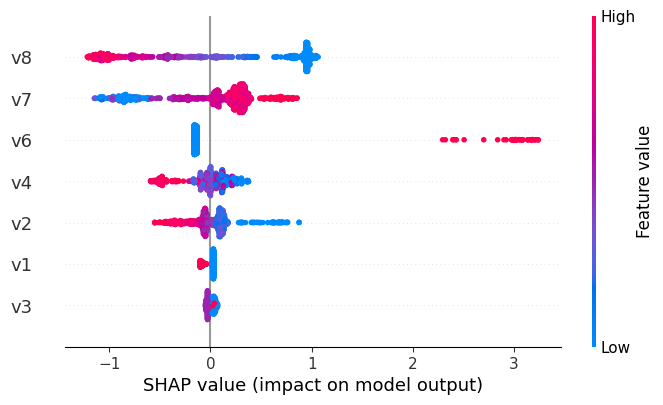

In [42]:
from credit_risk.visualization.shap_plots import plot_beeswarm

show_plot(plot_beeswarm(shap_exp, max_display=15))

### Interpretação do SHAP — LightGBM

**A `v8` é a variável de maior influência média nas previsões. Já a `v6` produz o maior aumento individual de risco, concentrado em poucos clientes.** O gráfico mostra essa diferença entre uma variável que influencia muitas previsões e outra que tem impacto intenso em um grupo pequeno.

Cada ponto representa um dos **1.000 clientes da amostra de teste** usada no gráfico. A cor indica o valor original da variável, do azul (baixo) ao rosa (alto). A posição horizontal indica quanto aquela variável contribuiu para a previsão do cliente: valores SHAP positivos elevam a PD prevista e valores negativos a reduzem. O eixo está em **log-odds**, por isso a distância horizontal não corresponde diretamente a pontos percentuais de PD.

#### Quanto cada variável contribui?

| Variável | Média do valor absoluto de SHAP | Participação na contribuição absoluta total |
|---|---:|---:|
| `v8` | 0,818 | 44,4% |
| `v7` | 0,374 | 20,3% |
| `v6` | 0,287 | 15,6% |
| `v4` | 0,148 | 8,0% |
| `v2` | 0,142 | 7,7% |
| `v1` | 0,042 | 2,3% |
| `v3` | 0,032 | 1,7% |

As três primeiras variáveis somam **80,3% da magnitude total das contribuições SHAP** nessa amostra. Esse percentual mede como o modelo distribui suas contribuições entre os preditores. A parcela dos eventos explicados e o ganho de Gini são medidas diferentes.

#### O que o gráfico revela sobre o risco?

- **`v8` — maior influência média.** Os pontos rosas se concentram à esquerda e os azuis à direita. Valores altos de `v8` tendem a reduzir o risco previsto, enquanto valores baixos tendem a elevá-lo.
- **`v7` — direção inversa à de `v8`.** Valores baixos aparecem predominantemente à esquerda, reduzindo o risco previsto. Valores altos tendem a elevá-lo.
- **`v6` — impacto forte em um grupo pequeno.** Para os **950 clientes com `v6 = 0`**, a contribuição mediana foi de **−0,145**. Para os **50 clientes com `v6 > 0`**, todas as contribuições foram positivas, entre **+2,29 e +3,24**, com mediana de **+3,02**. Isso explica por que `v6` aparece em terceiro lugar na média, mesmo tendo os pontos mais distantes à direita.

**Exemplo em escala de PD.** Para um cliente da amostra, o valor-base do modelo somado às contribuições das demais variáveis correspondia a uma PD de **19,1%**. Ao incluir a contribuição de `v6` (**+3,026** em log-odds), a PD final chegou a **83,0%**. Essa conta decompõe a previsão feita para aquele cliente. Para saber qual PD o modelo atribuiria se `v6` fosse zero, seria necessário alterar a entrada e calcular uma nova previsão.

In [43]:
from credit_risk.persistence.models import save_lightgbm

importancia_shap = mean_absolute_importance(shap_exp)
save_lightgbm(
    paths.lightgbm, modelo_lgb, best_params, resultados_lgb, historico,
    importancia_shap, trials=busca.trial_table(),
)
print("Modelo e resultados salvos!")

Modelo e resultados salvos!


## 13. Construção da régua de rating

O OptBinning ajusta cortes monotônicos sobre a PD de treino. A regra histórica exige oito bins antes da consolidação e combina os grupos originais 3 e 4. O grupo final 1 reúne as maiores PD. Os limites são aprendidos apenas no treino e aplicados com precisão integral.

### Discretização da PD no treino

In [44]:
from credit_risk.rating.scale import RatingScale

regua = RatingScale.fit(
    y_proba_train_lgb, y_train_lgb, max_bins=10, min_bin_size=0.05
)
print("Status:", regua.binning.status)
display(regua.binning.binning_table.build())

Status: OPTIMAL


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.03)",2742,0.342750,2697,45,0.016411,2.052577,0.681495,0.072811
1,"[0.03, 0.06)",1243,0.155375,1192,51,0.041030,1.110907,0.125451,0.014922
2,"[0.06, 0.12)",1227,0.153375,1140,87,0.070905,0.53222,0.035367,0.004369
3,"[0.12, 0.15)",575,0.071875,494,81,0.140870,-0.232569,0.004249,0.000530
4,"[0.15, 0.18)",705,0.088125,597,108,0.153191,-0.33087,0.010942,0.001361
5,"[0.18, 0.20)",460,0.057500,380,80,0.173913,-0.482511,0.016060,0.001988
6,"[0.20, 0.30)",630,0.078750,467,163,0.258730,-0.988076,0.109887,0.013203
7,"[0.30, inf)",418,0.052250,113,305,0.729665,-3.033579,0.957280,0.088050
8,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
9,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000


## Interpretação das faixas de risco do LightGBM

Na base de treino, as duas faixas de maior risco reuniram **13,1% dos clientes** e concentraram **50,9% dos eventos**. A taxa de evento observada aumentou em todas as faixas sucessivas, de **1,64%** na primeira para **72,97%** na última. Esse comportamento indica que o modelo ordenou os clientes por risco nessa amostra.

### Taxa de evento por faixa

| Faixa de PD prevista | Clientes | Eventos | Taxa de evento observada |
| --- | ---: | ---: | ---: |
| Abaixo de 3% | 2.742 | 45 | 1,64% |
| De 3% a menos de 6% | 1.243 | 51 | 4,10% |
| De 6% a menos de 12% | 1.227 | 87 | 7,09% |
| De 12% a menos de 15% | 575 | 81 | 14,09% |
| De 15% a menos de 18% | 705 | 108 | 15,32% |
| De 18% a menos de 20% | 460 | 80 | 17,39% |
| De 20% a menos de 30% | 630 | 163 | 25,87% |
| A partir de 30% | 418 | 305 | 72,97% |
| **Total** | **8.000** | **920** | **11,50%** |

*Os limites das faixas seguem o arredondamento exibido no notebook.*

### Concentração dos eventos

A faixa de menor risco reuniu **34,3% dos clientes** e apenas **4,9% dos eventos**. Já a faixa de maior risco reuniu **5,2% dos clientes** e concentrou **33,2% dos eventos**.

Os **305 eventos** da última faixa permitem duas leituras. Entre os **418 clientes dessa faixa**, 305 tiveram o evento, o que corresponde à **taxa observada de 72,97%**. Considerando os **920 eventos de toda a base**, esses mesmos 305 representam **33,2% do total de eventos**.

### WoE e IV

O **WoE** diminuiu de **+2,05** na primeira faixa para **−3,03** na última. Na convenção usada no projeto, valores positivos indicam maior concentração relativa de não eventos, enquanto valores negativos indicam maior concentração relativa de eventos.

O **IV total foi de 1,94**. A primeira e a última faixa responderam juntas por **84,4% desse valor**, mostrando que os extremos da régua foram os que mais contribuíram para a separação entre eventos e não eventos no treino.

### Calibração

Para avaliar se as probabilidades previstas estão próximas das frequências observadas, compare a **PD média dos clientes de cada faixa** com a **taxa de evento observada na mesma faixa**, preferencialmente na base de teste. Na última faixa, por exemplo, **30% é o limite inferior exibido**. A referência para avaliar os **72,97% observados** é a PD média dos 418 clientes classificados nessa faixa.

### Consolidação dos grupos originais 3 e 4

In [45]:
df_train_grupos = regua.classify(y_proba_train_lgb, y_train_lgb)
df_test_grupos = regua.classify(y_proba_test_lgb, y_test_lgb)
regua_pd = regua.limits()
print("\n========== RÉGUA DEFINITIVA ==========")
display(regua_pd.round(5))


========== RÉGUA DEFINITIVA ==========


,Grupos_Originais,PD_Limite_Inferior,PD_Limite_Superior
Grupo_Risco,,,
1,1,0.29963,1.00000
2,2,0.19687,0.29963
3,"3, 4",0.15048,0.19687
4,5,0.11877,0.15048
5,6,0.05687,0.11877
6,7,0.03403,0.05687
7,8,0.00000,0.03403


In [46]:
df_train_grupos = regua.classify(y_proba_train_lgb, y_train_lgb)
df_test_grupos = regua.classify(y_proba_test_lgb, y_test_lgb)
regua_pd = regua.limits()
print("\n========== RÉGUA DEFINITIVA ==========")
display(regua_pd.round(5))


========== RÉGUA DEFINITIVA ==========


,Grupos_Originais,PD_Limite_Inferior,PD_Limite_Superior
Grupo_Risco,,,
1,1,0.29963,1.00000
2,2,0.19687,0.29963
3,"3, 4",0.15048,0.19687
4,5,0.11877,0.15048
5,6,0.05687,0.11877
6,7,0.03403,0.05687
7,8,0.00000,0.03403


## 14. Comparação entre treino e teste

Aplique a mesma régua a ambas as amostras. As tabelas confrontam PD prevista, taxa observada e concentração de eventos em cada grupo. A validação exige taxas não crescentes no treino e também informa a monotonicidade observada no teste.

### Taxas de evento, lift e participação dos grupos

In [47]:
from credit_risk.evaluation.lift import (
    is_monotonic,
    risk_table,
    validate_train_monotonicity,
)

tabela_train = regua_pd.join(risk_table(df_train_grupos))
tabela_test = regua_pd.join(risk_table(df_test_grupos))
mono_train = validate_train_monotonicity(tabela_train)
mono_test = is_monotonic(tabela_test)
print("\nMonotonicidade treino:", mono_train)
print("Monotonicidade teste:", mono_test)
print("\n========== TREINO ==========")
display(tabela_train.round(4))
print("\n========== TESTE ==========")
display(tabela_test.round(4))


Monotonicidade treino: True
Monotonicidade teste: True

========== TREINO ==========


,Grupos_Originais,PD_Limite_Inferior,PD_Limite_Superior,Clientes,Eventos,PD_Min_Observada,PD_Max_Observada,PD_Media,Taxa_Evento,Lift,Captura_Eventos,Captura_Acumulada,Populacao_Acumulada,Lift_Acumulado
Grupo_Risco,,,,,,,,,,,,,,
1,1,0.2996,1.0000,418,305,0.3008,0.9198,0.6785,0.7297,6.3449,0.3315,0.3315,0.0522,6.3449
2,2,0.1969,0.2996,630,163,0.1969,0.2984,0.2197,0.2587,2.2498,0.1772,0.5087,0.1310,3.8832
3,"3, 4",0.1505,0.1969,1165,188,0.1505,0.1969,0.1735,0.1614,1.4032,0.2043,0.7130,0.2766,2.5777
4,5,0.1188,0.1505,575,81,0.1188,0.1505,0.1349,0.1409,1.2250,0.0880,0.8011,0.3485,2.2987
5,6,0.0569,0.1188,1227,87,0.0569,0.1187,0.0835,0.0709,0.6166,0.0946,0.8957,0.5019,1.7846
6,7,0.0340,0.0569,1243,51,0.0340,0.0569,0.0436,0.0410,0.3568,0.0554,0.9511,0.6572,1.4471
7,8,0.0000,0.0340,2742,45,0.0041,0.0340,0.0202,0.0164,0.1427,0.0489,1.0000,1.0000,1.0000



========== TESTE ==========


,Grupos_Originais,PD_Limite_Inferior,PD_Limite_Superior,Clientes,Eventos,PD_Min_Observada,PD_Max_Observada,PD_Media,Taxa_Evento,Lift,Captura_Eventos,Captura_Acumulada,Populacao_Acumulada,Lift_Acumulado
Grupo_Risco,,,,,,,,,,,,,,
1,1,0.2996,1.0000,101,70,0.3031,0.9159,0.6997,0.6931,6.0267,0.3043,0.3043,0.0505,6.0267
2,2,0.1969,0.2996,156,33,0.1970,0.2924,0.2181,0.2115,1.8395,0.1435,0.4478,0.1285,3.4850
3,"3, 4",0.1505,0.1969,288,60,0.1506,0.1967,0.1726,0.2083,1.8116,0.2609,0.7087,0.2725,2.6007
4,5,0.1188,0.1505,139,23,0.1189,0.1488,0.1355,0.1655,1.4388,0.1000,0.8087,0.3420,2.3646
5,6,0.0569,0.1188,308,23,0.0569,0.1185,0.0851,0.0747,0.6494,0.1000,0.9087,0.4960,1.8320
6,7,0.0340,0.0569,310,13,0.0340,0.0569,0.0434,0.0419,0.3647,0.0565,0.9652,0.6510,1.4827
7,8,0.0000,0.0340,698,8,0.0038,0.0340,0.0204,0.0115,0.0997,0.0348,1.0000,1.0000,1.0000


## Validação da régua de risco no treino e no teste

A régua separou os clientes em **sete grupos**, do **grupo 1 (maior risco)** ao **grupo 7 (menor risco)**. No teste, os três grupos de maior risco reuniram **27,25% dos clientes** e concentraram **70,87% dos eventos**. O resultado foi próximo ao do treino, em que **27,66% dos clientes** concentraram **71,30% dos eventos**.

| Grupo de risco | Taxa de evento no treino | Taxa de evento no teste | PD média no teste |
| --- | ---: | ---: | ---: |
| 1 (maior risco) | 72,97% | 69,31% | 69,97% |
| 2 | 25,87% | 21,15% | 21,81% |
| 3 | 16,14% | 20,83% | 17,26% |
| 4 | 14,09% | 16,55% | 13,55% |
| 5 | 7,09% | 7,47% | 8,51% |
| 6 | 4,10% | 4,19% | 4,34% |
| 7 (menor risco) | 1,64% | 1,15% | 2,04% |

### Ordenação dos grupos

O resultado `Monotonicidade: True` indica que a taxa observada de evento diminuiu a cada passagem do grupo 1 ao grupo 7, tanto no treino quanto no teste. A separação foi mais evidente nos extremos. No teste, o grupo 1 registrou **70 eventos em 101 clientes**, enquanto o grupo 7 registrou **8 eventos em 698 clientes**. Já os grupos 2 e 3 ficaram próximos, com taxas de **21,15% e 20,83%**, uma diferença de apenas **0,32 ponto percentual**.

### Captura de eventos e lift

No grupo 1, **69,31%** é a taxa de evento entre os clientes do grupo (70 de 101). Já **30,43%** é a parcela de todos os eventos do teste capturada por esse grupo (70 de 230). Como a taxa geral de evento foi de **11,50%**, o **lift de 6,03** indica que a frequência de eventos no grupo 1 foi aproximadamente seis vezes a média da base.

Ao incluir os grupos 1 a 3, a captura chegou a **163 dos 230 eventos**, abrangendo **545 dos 2.000 clientes**. Isso corresponde a um **lift acumulado de 2,60**.

### Calibração das probabilidades

No grupo 1, a **PD média de 69,97%** ficou próxima da **taxa observada de 69,31%**. Nos grupos 3 e 4, o modelo subestimou o risco observado no teste em **3,57 e 3,00 pontos percentuais**, respectivamente. Assim, a régua preservou a ordenação de risco nas duas amostras, e os maiores desvios entre previsão e ocorrência no teste apareceram nesses dois grupos intermediários.

### Ordenação de risco e PD observada

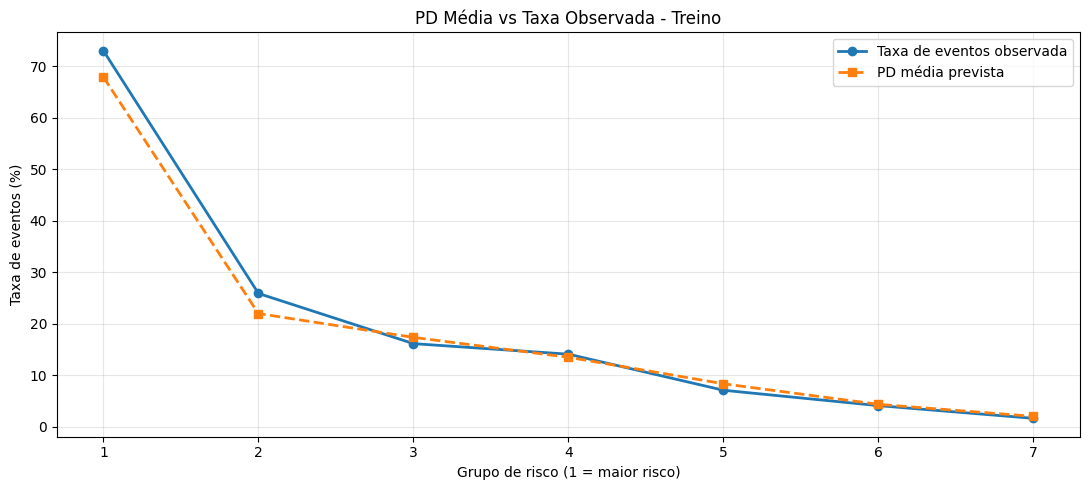

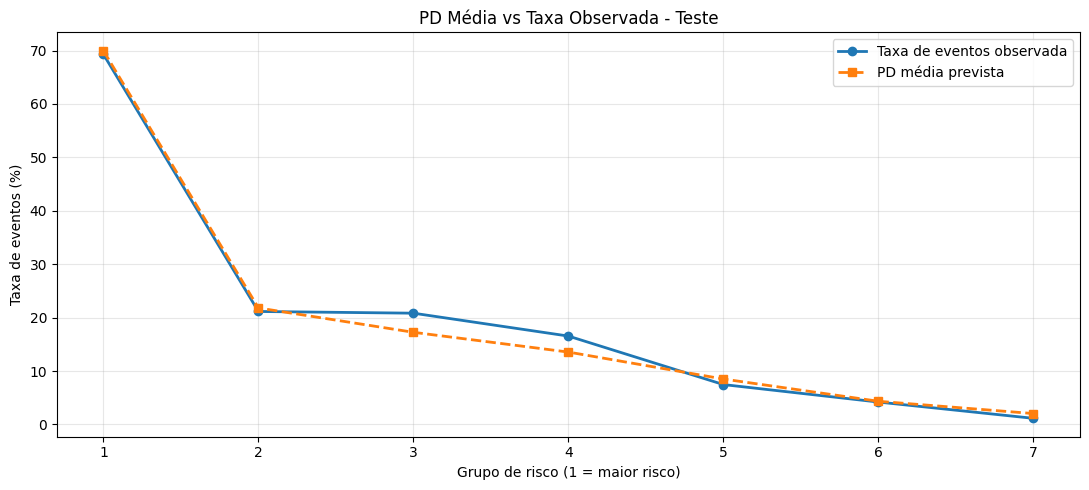

In [48]:
from credit_risk.visualization.rating import plot_rates

show_plot(plot_rates(tabela_train, "PD Média vs Taxa Observada - Treino"))
show_plot(plot_rates(tabela_test, "PD Média vs Taxa Observada - Teste"))

### Lift por grupo e captura acumulada de eventos

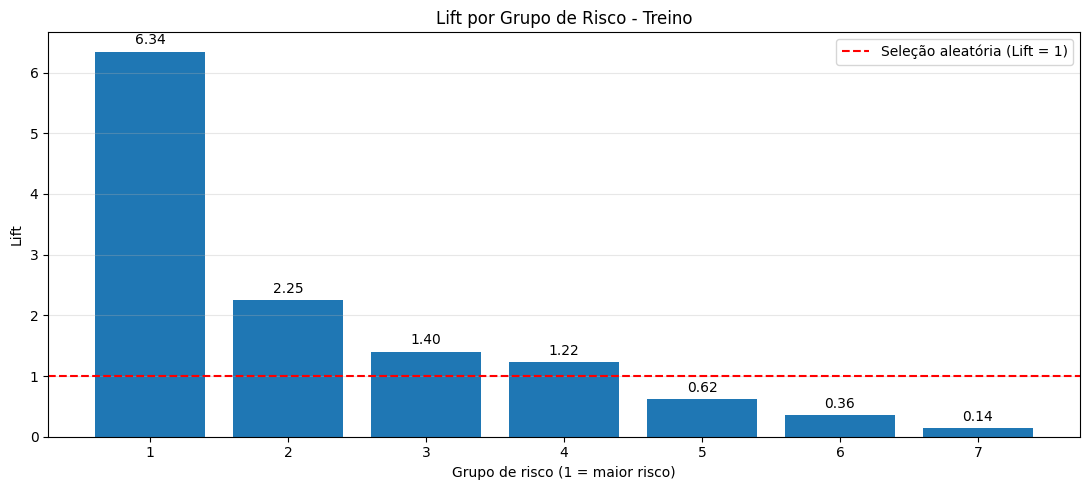

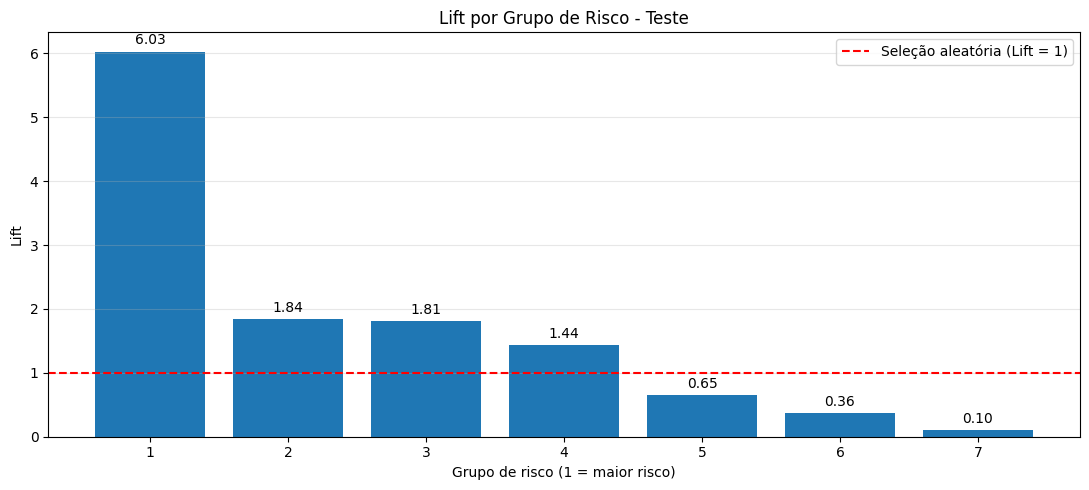

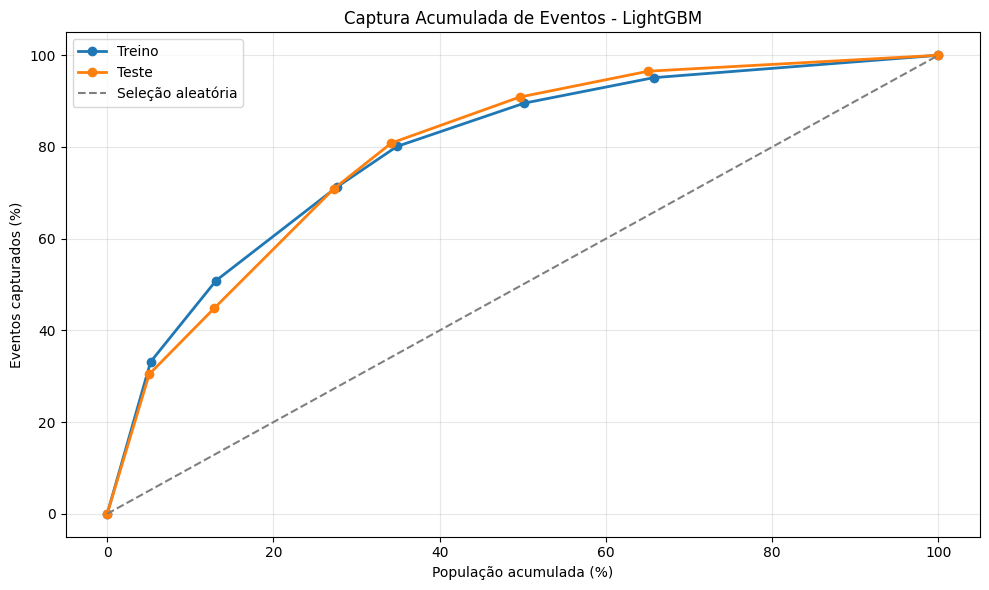

In [49]:
from credit_risk.visualization.rating import plot_lift, plot_capture

show_plot(plot_lift(tabela_train, "Lift por Grupo de Risco - Treino"))
show_plot(plot_lift(tabela_test, "Lift por Grupo de Risco - Teste"))
show_plot(plot_capture(tabela_train, tabela_test))

## Lift por grupo de risco e captura acumulada de eventos

No teste, os **27,25% dos clientes classificados nos três grupos de maior risco concentraram 70,87% dos eventos**. Uma seleção aleatória da mesma proporção de clientes capturaria, em média, 27,25% dos eventos. Portanto, priorizar esses três grupos apresentou **lift acumulado de 2,60**.

### Lift por grupo

Nos dois primeiros gráficos, cada barra compara a **taxa de evento de um grupo** com a **taxa geral da respectiva base**. A linha vermelha marca o lift igual a 1. Acima dela, o grupo apresenta risco superior à média. Abaixo dela, o risco é inferior à média.

- **Grupo 1.** O lift foi de **6,34 no treino** e **6,03 no teste**. No teste, **69,31%** dos clientes desse grupo tiveram o evento, frente a **11,50%** na base. Ou seja, a frequência de eventos foi aproximadamente seis vezes a média.
- **Grupos intermediários.** Os grupos 2 a 4 ficaram acima da média nas duas amostras. No teste, os grupos 2 e 3 tiveram lifts próximos (**1,84 e 1,81**), indicando pouca diferença de risco observado entre essas duas faixas.
- **Grupo 7.** O lift foi de **0,10 no teste**. A taxa de evento desse grupo foi de **1,15%**, aproximadamente um décimo da taxa geral.

### Captura acumulada

O terceiro gráfico mostra como a captura aumenta ao incluir os grupos em ordem de risco, começando pelo grupo 1. O eixo horizontal indica o percentual de clientes incluídos, e o vertical indica o percentual de todos os eventos capturados.

| Grupos incluídos | Clientes incluídos no teste | Eventos capturados no teste |
| --- | ---: | ---: |
| Grupo 1 | 5,05% | 30,43% |
| Grupos 1 e 2 | 12,85% | 44,78% |
| Grupos 1 a 3 | 27,25% | 70,87% |
| Grupos 1 a 4 | 34,20% | 80,87% |

A inclusão do **grupo 4** ilustra o ganho ao ampliar a cobertura. Com **139 clientes adicionais**, a captura passou de **163 para 186 dos 230 eventos** do teste. As curvas de treino e teste ficaram próximas, sobretudo a partir do terceiro grupo, indicando que a concentração de eventos nas faixas de maior risco também se manteve na amostra de teste.

### Comparação entre treino e teste

In [50]:
from credit_risk.evaluation.lift import compare_ratings

comparacao_rating = compare_ratings(tabela_train, tabela_test)
print("\n========== COMPARAÇÃO DA RÉGUA ==========")
display(comparacao_rating.round(4))


========== COMPARAÇÃO DA RÉGUA ==========


,Clientes_Treino,Clientes_Teste,PD_Treino,PD_Teste,Taxa_Evento_Treino,Taxa_Evento_Teste,Lift_Treino,Lift_Teste,Diferenca_Evento_pp
Grupo_Risco,,,,,,,,,
1,418,101,0.6785,0.6997,0.7297,0.6931,6.3449,6.0267,-3.6596
2,630,156,0.2197,0.2181,0.2587,0.2115,2.2498,1.8395,-4.7192
3,1165,288,0.1735,0.1726,0.1614,0.2083,1.4032,1.8116,4.6960
4,575,139,0.1349,0.1355,0.1409,0.1655,1.2250,1.4388,2.4598
5,1227,308,0.0835,0.0851,0.0709,0.0747,0.6166,0.6494,0.3771
6,1243,310,0.0436,0.0434,0.0410,0.0419,0.3568,0.3647,0.0906
7,2742,698,0.0202,0.0204,0.0164,0.0115,0.1427,0.0997,-0.4950


## Comparação da régua de risco entre treino e teste

A régua manteve a **ordenação dos sete grupos** na base de teste. A taxa de evento caiu de **69,31% no grupo 1** para **1,15% no grupo 7**. A principal mudança ocorreu entre os **grupos 2 e 3**: a diferença de risco observado entre eles passou de **9,73 pontos percentuais no treino** para apenas **0,32 ponto percentual no teste**.

A coluna **`Diferenca_Evento_pp`** mostra a taxa de evento do teste menos a taxa de evento do treino, em pontos percentuais. Um valor positivo indica que a frequência de eventos aumentou no teste.

| Grupo | Taxa de evento no treino | Taxa de evento no teste | Variação |
| --- | ---: | ---: | ---: |
| 1 | 72,97% | 69,31% | −3,66 p.p. |
| 2 | 25,87% | 21,15% | −4,72 p.p. |
| 3 | 16,14% | 20,83% | +4,70 p.p. |
| 4 | 14,09% | 16,55% | +2,46 p.p. |
| 5 | 7,09% | 7,47% | +0,38 p.p. |
| 6 | 4,10% | 4,19% | +0,09 p.p. |
| 7 | 1,64% | 1,15% | −0,50 p.p. |

**Separação de risco.** O grupo 1 continuou concentrando os clientes de maior risco, com lift de **6,34 no treino** e **6,03 no teste**. Nos grupos 2 e 3, os lifts de teste ficaram próximos (**1,84 e 1,81**). Assim, a régua distinguiu bem os extremos, mas a separação observada entre essas duas faixas intermediárias foi pequena no teste.

**Calibração.** Para avaliar a precisão da PD, compare `PD_Teste` com `Taxa_Evento_Teste` dentro de cada grupo. No grupo 1, a **PD média de 69,97%** ficou próxima dos **69,31% observados**. Os maiores desvios ocorreram nos grupos **3 e 4**, nos quais a taxa observada superou a PD média em **3,57 e 3,00 pontos percentuais**, respectivamente.

### Persistência dos limites, tabelas e classificações

In [51]:
from credit_risk.persistence.rating import save_rating_artifacts

save_rating_artifacts(
    paths.rating, regua, tabela_train, tabela_test,
    df_train_grupos, df_test_grupos, comparacao_rating,
)
print("Todos os artefatos foram salvos com sucesso!")

Todos os artefatos foram salvos com sucesso!


## 1. Conclusão executiva

O **LightGBM é o modelo recomendado para a régua de risco de crédito do case**. Na base de teste, ordenou melhor os clientes por risco do que a regressão logística, com **AUC de 0,8434 contra 0,8255** e **KS de 0,5476 contra 0,5019**. O ganho de Gini foi de **3,57 pontos**, com intervalo de confiança de 95% entre **1,28 e 5,89 pontos** no bootstrap pareado. O LightGBM também apresentou menor erro nas probabilidades previstas, medido pelo Brier Score e pela log loss.

**Na prática, a régua permite priorizar a análise de crédito.** Na amostra de teste, os três grupos de maior risco reuniram **545 dos 2.000 clientes (27,25%)** e concentraram **163 dos 230 eventos (70,87%)**. No treino, a mesma parcela aproximada da carteira concentrou **71,30% dos eventos**. O grupo de maior risco se destacou nas duas amostras. No teste, sua taxa de evento foi de **69,31%**, cerca de **seis vezes** a média da carteira, de **11,50%**.

Os sete grupos mantiveram a ordem de risco no teste, mas a distinção entre os **grupos 2 e 3** foi pequena: as taxas observadas foram de **21,15% e 20,83%**. Além disso, nos grupos 3 e 4, a taxa observada superou a PD média prevista em **3,57 e 3,00 pontos percentuais**, respectivamente.

**A aplicação mais bem sustentada pelos resultados é a priorização de análises pelos grupos de maior risco.** Antes de definir políticas de concessão distintas para faixas vizinhas, recomenda-se validar a régua em um período posterior, com atenção à separação entre os grupos 2 e 3 e à calibração das PDs intermediárias.


## Recomendações de uso na política de crédito

Recomenda-se usar a régua do LightGBM para **definir quais propostas passam por análise adicional e quais seguem o fluxo padrão**. Como ponto de partida para um piloto, priorizar os **grupos 1 a 3** encaminharia **27,25% das propostas para revisão**. Na base de teste, essa parcela concentrou **70,87% dos eventos**. A escolha do corte depende da capacidade da equipe e do custo da revisão.

| Grupo de risco | Taxa de evento no teste | Tratamento proposto |
| --- | ---: | --- |
| **1** | **69,31%** | Dar prioridade máxima à revisão. Verificar capacidade de pagamento, endividamento e exposição total antes de conceder crédito ou ampliar o limite. |
| **2 e 3** | **21,15% e 20,83%** | Aplicar a mesma regra inicial de revisão. A diferença observada foi de apenas 0,32 ponto percentual. Usar o valor solicitado e a capacidade de pagamento para definir quais propostas exigem aprovação por uma alçada superior. |
| **4** | **16,55%** | Adotar revisão seletiva para propostas de maior exposição. Acompanhar a calibração do grupo, cuja PD média foi de 13,55%. |
| **5** | **7,47%** | Manter o fluxo padrão de concessão e avaliar pedidos de aumento de limite conforme renda, endividamento e histórico de pagamento. |
| **6 e 7** | **4,19% e 1,15%** | Testar um fluxo simplificado para propostas que já atendam aos critérios de elegibilidade, capacidade de pagamento e limite de exposição. |

### Como definir o corte de revisão

Se a equipe puder revisar cerca de **5% das propostas**, o grupo 1 é o primeiro candidato. No teste, ele reuniu **101 clientes e 70 dos 230 eventos**. Com capacidade próxima de **27%**, incluir os grupos 2 e 3 elevaria a cobertura para **545 clientes e 163 eventos**. Incluir também o grupo 4 exigiria **139 revisões adicionais** para alcançar outros **23 eventos observados**. Esses números medem a concentração histórica de eventos. A redução efetiva de perdas depende das decisões tomadas após a revisão.

### Como validar a política

Antes da implantação, aplicar a régua em uma **safra posterior** e comparar os encaminhamentos propostos com as decisões da política vigente. No piloto, acompanhar **volume de revisões, taxa de aprovação, tempo de resposta e perda por valor concedido**. Para definir limites, preços ou cortes de recusa, incorporar a exposição, a perda em caso de inadimplência e a margem da operação. Acompanhar também a PD média e a taxa observada por grupo, com atenção aos **grupos 3 e 4**, nos quais o modelo subestimou o risco no teste.